<div style='text-align:center;'>
  <img src="CDAM.PNG" width="1200">
</div>

<div style="text-align: center; font-weight: bold; font-size: 22px; color: #1a1a1a;">
  <div style="color: #0B5394; font-size: 38px;">CENTER FOR DATA ANALYTICS AND MODELLING (CDAM)</div>
  <div style="color: #38761D; font-size: 24px;">INTERMEDIATE PYTHON TRAINING: SESSION FIVE; IMPLEMENTATION OF MACHINE LEARNING ALGORITHMS</div>
  <br>
  <div style="color: #CC0000; font-size: 22px;">FACILITATOR:</div>
  <div style="color: #000000; font-size: 20px;">VICTOR WANDERA LUMUMBA</div>
  <div style="color: #3D85C6; font-size: 20px;">Chuka University, Kenya</div>
  <br>
  <div style="color: #6AA84F; font-size: 18px;">Date:</div>
  <div style="color: #351C75; font-size: 18px;">August 13, 2025</div>
</div>

## **1. Problem Definition**

You aim to predict **loan default status** (`Status` = Yes or No) based on customer demographic, financial, and loan-related features such as marital status, gender, loan type, loan purpose, creditworthiness, loan amount, property value, income, credit score, and age. This is a **binary classification problem**, where the target variable has two classes:

* **Yes**: Loan repaid successfully (no default)
* **No**: Loan defaulted

The machine learning task is **supervised classification**, meaning the model is trained using historical labeled data to predict the class of new, unseen data.

## **2. Data Understanding and Preparation**

Before modeling, the dataset must be **explored and preprocessed**:

1. **Feature Types**

   * **Categorical variables**: `Marital_Status`, `Gender`, `loan_type`, `loan_purpose`, `Credit_Worthiness`, `business_or_commercial`, `credit_type`, `age`
   * **Numerical variables**: `loan_amount`, `rate_of_interest`, `term`, `property_value`, `income`, `Credit_Score`

2. **Data Cleaning**

   * Handle missing values, if any.
   * Remove duplicates.
   * Check for outliers, especially in financial columns like `loan_amount` or `income`.

3. **Encoding Categorical Data**

   * Convert categories to numerical form (e.g., One-Hot Encoding for `loan_type`, Label Encoding for binary fields).

4. **Feature Scaling**

   * **SVM** and **KNN** are sensitive to feature scales.
   * Apply **standardization** (zero mean, unit variance) or **min-max scaling** to numerical features to ensure no single variable dominates due to its magnitude.

5. **Train-Test Split**

   * Split the data into training and testing sets (e.g., 70%-80% for training, 20%-30% for testing) to evaluate performance.

## **3. Support Vector Machine (SVM)**

SVM is a powerful classification algorithm that works by finding the **optimal hyperplane** that separates data points of different classes with the **maximum margin**.

### **How It Works**

* Each data point is plotted in an n-dimensional space (n = number of features).
* The algorithm tries to find a **decision boundary** (hyperplane) that separates the two classes with the largest possible distance from the nearest points in each class (called **support vectors**).
* SVM can use **kernels** to handle non-linear relationships by mapping data to a higher-dimensional space.

### **Key Parameters**

* **C (Regularization parameter)**: Controls the trade-off between a smooth decision boundary and classifying training points correctly.

  * Small C → Smoother decision boundary, less overfitting.
  * Large C → Fits training data more closely, risk of overfitting.
* **Kernel**:

  * **Linear**: Works well for linearly separable data.
  * **Polynomial**: Captures polynomial relationships.
  * **RBF (Radial Basis Function)**: Popular for non-linear data.
* **Gamma**: Defines influence of a single training example; high gamma → close fit to training data.

### **Advantages**

* Effective in high-dimensional spaces.
* Works well when there is a clear margin of separation.
* Can handle non-linear boundaries with kernels.

### **Limitations**

* Computationally expensive for large datasets.
* Sensitive to parameter choices and scaling.

## **4. K-Nearest Neighbors (KNN)**

KNN is a **non-parametric, instance-based** learning algorithm, often called a **lazy learner** because it doesn’t build a model during training. Instead, it stores the training data and makes predictions at query time.

### **How It Works**

* Choose a value for **k** (number of neighbors to consider).
* For a new data point:

  * Calculate the **distance** (usually Euclidean) between it and all training samples.
  * Select the **k closest points**.
  * The class is determined by **majority voting** among these neighbors.

### **Key Parameters**

* **k (Number of Neighbors)**:

  * Small k → Model sensitive to noise, more flexible.
  * Large k → More stable, smoother boundaries but may miss complex patterns.
* **Distance Metric**:

  * Euclidean (most common), Manhattan, or Minkowski distances.
* **Weighting**:

  * Uniform: All neighbors have equal influence.
  * Distance-weighted: Closer neighbors have more influence.

### **Advantages**

* Simple to understand and implement.
* No need for model assumptions.
* Works well with well-separated classes.

### **Limitations**

* Computationally expensive for large datasets (needs distance calculation for all points).
* Performance can degrade with high-dimensional data (curse of dimensionality).
* Sensitive to irrelevant features and scaling.

## **5. Model Evaluation**

Since the problem is classification, you will evaluate **SVM** and **KNN** using:

* **Accuracy**: Proportion of correct predictions.
* **Precision**: Correct positive predictions over all predicted positives.
* **Recall (Sensitivity)**: Correct positive predictions over all actual positives.
* **F1-Score**: Harmonic mean of precision and recall.
* **ROC-AUC**: Measures ability to distinguish between classes.

A **confusion matrix** will help visualize correct and incorrect predictions.

## **6. Workflow Summary**

1. **Preprocessing**: Clean, encode, and scale data.
2. **Train-Test Split**: Ensure fair evaluation.
3. **Model Selection**:

   * Train SVM with different kernels and C values.
   * Train KNN with different k values.
4. **Hyperparameter Tuning**:

   * Use **GridSearchCV** or **RandomizedSearchCV** for systematic tuning.
5. **Evaluation**:

   * Compare performance metrics.
   * Select the best-performing model.

## **7. Practical Tips for Your Dataset**

* The dataset has **mixed categorical and numeric data**, so preprocessing is critical.
* Since SVM and KNN both require scaling, apply `StandardScaler` or `MinMaxScaler`.
* Credit-related features like `Credit_Score`, `Credit_Worthiness`, and `income` may be highly predictive — test feature importance.
* If dataset is imbalanced (more Yes than No), consider **SMOTE** oversampling or class weighting.

In [2]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("Loan_Default2.csv")
df.head(20)

,loan_limit,Marital_Status,Gender,loan_type,loan_purpose,Credit_Worthiness,business_or_commercial,loan_amount,rate_of_interest,term,property_value,income,credit_type,Credit_Score,age,Status
0,1,1,1,1,1,1,0,116500,4.045476,360.0,1.180000e+05,1740.000000,4,758,2,1
1,1,3,1,2,1,1,1,206500,4.045476,360.0,4.978935e+05,4980.000000,3,552,5,1
2,1,3,1,1,1,1,0,406500,4.560000,360.0,5.080000e+05,9480.000000,4,834,3,0
3,1,2,1,1,4,1,0,456500,4.250000,360.0,6.580000e+05,11880.000000,4,587,4,0
4,1,2,0,1,1,1,0,696500,4.000000,360.0,7.580000e+05,10440.000000,2,602,2,0
5,1,2,0,1,1,1,0,706500,3.990000,360.0,1.008000e+06,10080.000000,4,864,3,0
6,1,3,0,1,3,1,0,346500,4.500000,360.0,4.380000e+05,5040.000000,4,860,5,0
7,0,3,0,1,4,1,0,266500,4.125000,360.0,3.080000e+05,3780.000000,1,863,5,0
8,1,3,0,1,3,1,0,376500,4.875000,360.0,4.780000e+05,5580.000000,1,580,5,0
9,1,3,1,3,3,1,0,436500,3.490000,360.0,6.880000e+05,6720.000000,1,788,5,0


### View the Dimension of the Data

In [17]:
print(df.shape)

(148670, 16)


The data frame has 16 variable with 148670 observation. The target variable is column 16

### View the Structure of the Data

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 16 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   loan_limit              148670 non-null  int64  
 1   Marital_Status          148670 non-null  int64  
 2   Gender                  148670 non-null  int64  
 3   loan_type               148670 non-null  int64  
 4   loan_purpose            148670 non-null  int64  
 5   Credit_Worthiness       148670 non-null  int64  
 6   business_or_commercial  148670 non-null  int64  
 7   loan_amount             148670 non-null  int64  
 8   rate_of_interest        148670 non-null  float64
 9   term                    148670 non-null  float64
 10  property_value          148670 non-null  float64
 11  income                  148670 non-null  float64
 12  credit_type             148670 non-null  int64  
 13  Credit_Score            148670 non-null  int64  
 14  age                 

## Summary Statistics

In [4]:
df.describe()

,loan_limit,Marital_Status,Gender,loan_type,loan_purpose,Credit_Worthiness,business_or_commercial,loan_amount,rate_of_interest,term,property_value,income,credit_type,Credit_Score,age,Status
count,148670.000000,148670.000000,148670.000000,148670.000000,148670.000000,148670.000000,148670.000000,1.486700e+05,148670.000000,148670.000000,1.486700e+05,148670.000000,148670.000000,148670.000000,148670.000000,148670.000000
mean,0.910392,2.671676,0.538138,1.337876,2.881166,0.957449,0.139652,3.311177e+05,4.045476,335.136582,4.978935e+05,6957.338876,2.334862,699.789103,4.137445,0.246445
std,0.285620,0.572363,0.498545,0.649571,1.142986,0.201842,0.346626,1.839093e+05,0.487764,58.401029,3.411696e+05,6293.492004,1.194302,115.875857,1.417438,0.430942
min,0.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,1.650000e+04,0.000000,96.000000,8.000000e+03,0.000000,1.000000,500.000000,1.000000,0.000000
25%,1.000000,2.000000,0.000000,1.000000,2.000000,1.000000,0.000000,1.965000e+05,3.750000,360.000000,2.880000e+05,3840.000000,1.000000,599.000000,3.000000,0.000000
50%,1.000000,3.000000,1.000000,1.000000,3.000000,1.000000,0.000000,2.965000e+05,4.045476,360.000000,4.580000e+05,6000.000000,2.000000,699.000000,4.000000,0.000000
75%,1.000000,3.000000,1.000000,1.000000,4.000000,1.000000,0.000000,4.365000e+05,4.250000,360.000000,5.980000e+05,8280.000000,4.000000,800.000000,5.000000,0.000000
max,1.000000,3.000000,1.000000,3.000000,4.000000,1.000000,1.000000,3.576500e+06,8.000000,360.000000,1.650800e+07,578580.000000,4.000000,900.000000,7.000000,1.000000


### Grouped Summary Statistics 

In [5]:
grouped_stats = df.groupby('Status')[['loan_amount', 'rate_of_interest', 'property_value']].agg(['mean', 'median', 'std', 'min', 'max'])
grouped_stats

loan_amount                                           \
                 mean    median            std    min      max   
Status                                                           
0       334990.774875  306500.0  174916.570573  26500  3006500   
1       319275.184912  276500.0  208576.810054  16500  3576500   

       rate_of_interest                                 property_value  \
                   mean    median       std    min  max           mean   
Status                                                                   
0              4.044931  3.990000  0.561356  0.000  8.0  505605.928600   
1              4.047141  4.045476  0.042883  3.125  5.5  474311.082677   

                                                        
             median            std     min         max  
Status                                                  
0       428000.0000  342781.404432  8000.0   9268000.0  
1       497893.4657  335098.521332  8000.0  16508000.0

### View the Bar Graph of the Dependent Variable

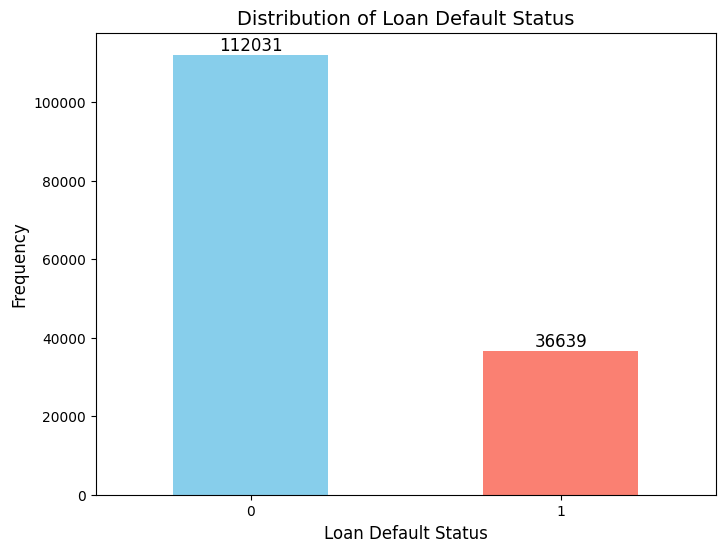

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
# Get the counts of each category
value_counts = df['Status'].value_counts()

# Create a bar graph with different colors
colors = ['skyblue', 'salmon']  # Adjust colors as needed
ax = value_counts.plot(kind='bar', color=colors, figsize=(8, 6))

# Add values on top of each bar
for i in ax.containers:
    ax.bar_label(i, label_type='edge', fontsize=12)

# Customize the plot
plt.title('Distribution of Loan Default Status', fontsize=14)
plt.xlabel('Loan Default Status', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=0, fontsize=10)  # Rotate the x-axis labels if needed
plt.yticks(fontsize=10)
plt.show()


## Check Zero and Near Zero Variance

### Near Zero Variance

In [ ]:
#pip install sklearn

In [8]:
from sklearn.feature_selection import VarianceThreshold
import pandas as pd

# Assuming 'data' is your pandas DataFrame and you want to exclude the 16th column (index 15)
X = df.drop(df.columns[15], axis=1)  # Dropping the 16th column

# Initialize VarianceThreshold with a small threshold (near-zero variance)
selector = VarianceThreshold(threshold=1e-4)

# Fit the model to find near-zero variance predictors
selector.fit(X)

# Get the boolean mask indicating which columns have non-zero variance
non_zero_variance_mask = selector.get_support()

# Create a DataFrame showing the variance metrics
nzv_metrics = pd.DataFrame({
    'Feature': X.columns,
    'Variance': X.var(),
    'NearZeroVariance': ~non_zero_variance_mask  # True if near-zero variance
})

# Print the results
print(nzv_metrics)

                                       Feature      Variance  NearZeroVariance
loan_limit                          loan_limit  8.157884e-02             False
Marital_Status                  Marital_Status  3.275991e-01             False
Gender                                  Gender  2.485472e-01             False
loan_type                            loan_type  4.219428e-01             False
loan_purpose                      loan_purpose  1.306416e+00             False
Credit_Worthiness            Credit_Worthiness  4.074033e-02             False
business_or_commercial  business_or_commercial  1.201498e-01             False
loan_amount                        loan_amount  3.382263e+10             False
rate_of_interest              rate_of_interest  2.379139e-01             False
term                                      term  3.410680e+03             False
property_value                  property_value  1.163967e+11             False
income                                  income  3.96

### Zero Variance

In [9]:
import pandas as pd
X = df.drop(df.columns[15], axis=1)  # Dropping the 17th column

# Calculate variance for each feature
variance = X.var()

# Identify zero variance predictors
zero_variance_mask = variance == 0

# Create a DataFrame showing the variance metrics
variance_metrics = pd.DataFrame({
    'Feature': X.columns,
    'Variance': variance,
    'ZeroVariance': zero_variance_mask  # True if zero variance
})

# Print the results
print(variance_metrics[variance_metrics['ZeroVariance'] == True])

Empty DataFrame
Columns: [Feature, Variance, ZeroVariance]
Index: []


### Data Partitioning

In [10]:
from sklearn.model_selection import train_test_split

# Separate features (X) and target variable (y)
X = df.drop("Status", axis=1) 
y = df["Status"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (104069, 15)
Testing set shape: (44601, 15)


### View the Available Models 

In [11]:
from sklearn.utils import all_estimators
# Get all classifiers and regressors
estimators = all_estimators()
# Extract the names of the models
model_names = [name for name, _ in estimators]
# Display the list of model names
print(model_names)

['ARDRegression', 'AdaBoostClassifier', 'AdaBoostRegressor', 'AdditiveChi2Sampler', 'AffinityPropagation', 'AgglomerativeClustering', 'BaggingClassifier', 'BaggingRegressor', 'BayesianGaussianMixture', 'BayesianRidge', 'BernoulliNB', 'BernoulliRBM', 'Binarizer', 'Birch', 'BisectingKMeans', 'CCA', 'CalibratedClassifierCV', 'CategoricalNB', 'ClassifierChain', 'ColumnTransformer', 'ComplementNB', 'CountVectorizer', 'DBSCAN', 'DecisionTreeClassifier', 'DecisionTreeRegressor', 'DictVectorizer', 'DictionaryLearning', 'DummyClassifier', 'DummyRegressor', 'ElasticNet', 'ElasticNetCV', 'EllipticEnvelope', 'EmpiricalCovariance', 'ExtraTreeClassifier', 'ExtraTreeRegressor', 'ExtraTreesClassifier', 'ExtraTreesRegressor', 'FactorAnalysis', 'FastICA', 'FeatureAgglomeration', 'FeatureHasher', 'FeatureUnion', 'FixedThresholdClassifier', 'FrozenEstimator', 'FunctionTransformer', 'GammaRegressor', 'GaussianMixture', 'GaussianNB', 'GaussianProcessClassifier', 'GaussianProcessRegressor', 'GaussianRandomPr

### Model Fitting

### Support Vector Machines (SVM)

In [12]:
from sklearn.datasets import make_classification
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [13]:
from sklearn.svm import SVC
model_svm = SVC()
model_svm.fit(X_train, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


### Classification Score

In [14]:
model_svm.score(X_test, y_test)

0.7823367189076478

In [15]:
y_pred = model_svm.predict(X_test)

In [16]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[33298,   389],
       [ 9319,  1595]], dtype=int64)

In [22]:
# Evaluate the model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on the test set with best parameters: {accuracy:.4f}")

Accuracy on the test set with best parameters: 0.7823


Text(0.5, 1.0, 'Confusion Matrix for Support Vector Machines')

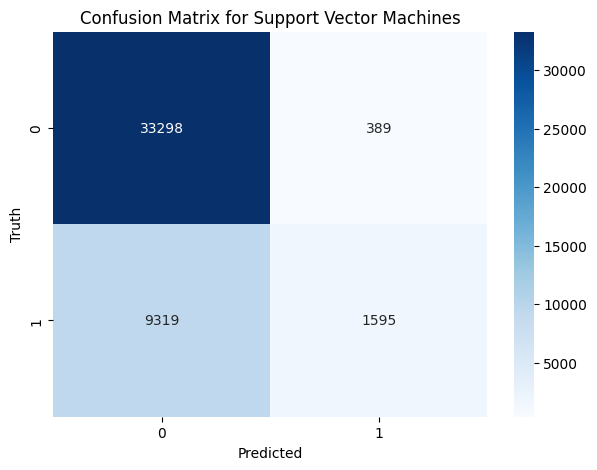

In [23]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize=(7,5))
sn.heatmap(cm, annot=True,fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title("Confusion Matrix for Support Vector Machines")

In [24]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, target_names=["No","Yes"]))

              precision    recall  f1-score   support

          No       0.78      0.99      0.87     33687
         Yes       0.80      0.15      0.25     10914

    accuracy                           0.78     44601
   macro avg       0.79      0.57      0.56     44601
weighted avg       0.79      0.78      0.72     44601



### Obtain the ROC and AUC

In [ ]:
# Train the SVM model
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
svm_model = SVC(kernel='linear', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

In [ ]:
# Predict probabilities
y_pred_prob = svm_model.predict_proba(X_test)[:, 1]

In [ ]:
# Compute AUC
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC: {auc}")

In [ ]:
# Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for SVM')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Obtain Other Performance Metrics

In [24]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.contingency_tables import mcnemar


# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Confusion matrix values
TN, FP, FN, TP = cm.ravel()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred)
# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2


In [25]:
# Print the results
print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

Confusion Matrix:
[[69  0]
 [33  0]]
Accuracy: 0.6765
Sensitivity: 0.0000
Specificity: 1.0000
Positive Predictive Value: 0.0000
Negative Predictive Value: 0.6765
F1 Score: 0.0000
Cohen's Kappa: 0.0000
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.0000000
Balanced Accuracy: 0.5000


The SVM model produced a confusion matrix indicating 69 true negatives, 33 false negatives, and zero true positives or false positives. This led to an accuracy of 67.65%, which corresponds to the proportion of correctly classified samples. However, the sensitivity (true positive rate) is 0.00%, meaning the model failed to correctly identify any positive cases. In contrast, the specificity (true negative rate) is 100.00%, reflecting that the model perfectly identified all negative cases. This imbalance between sensitivity and specificity suggests that the model is heavily biased toward the negative class. The positive predictive value (precision) is 0.00%, indicating no correct positive predictions, while the negative predictive value is 67.65%, consistent with the overall accuracy. The F1 score, which balances precision and recall, is also 0.00% due to the absence of true positive predictions. Cohen's Kappa, measuring the agreement between the predicted and actual classifications beyond chance, is 0.00%, showing no real predictive power beyond random guessing. The No Information Rate (NIR), reflecting the accuracy of a model that always predicts the majority class, is equal to the model’s accuracy, implying that the model performs no better than predicting all cases as negative. McNemar's Test yields a p-value of 0.0000000, suggesting a statistically significant difference between the errors in the positive and negative classes. Lastly, the balanced accuracy, which averages sensitivity and specificity, is 50.00%, underscoring the equal weighting of correct and incorrect classifications across both classes. Overall, the model shows substantial issues with class imbalance, indicating a need for further tuning, possibly with adjustments in class weights, sampling techniques, or alternative model selection to improve the identification of positive cases.

## Features Importance Plot

In [26]:
import numpy as np
import matplotlib.pyplot as plt
coefficients = svm_model.coef_.flatten()

# Sorting features by their importance (absolute value of the coefficients)
sorted_idx = np.argsort(np.abs(coefficients))[::-1]
sorted_coefficients = coefficients[sorted_idx]
sorted_features = X_train.columns[sorted_idx]
FIMP = sorted_features

In [27]:
import pandas as pd
FIMP = pd.DataFrame(FIMP)
FIMP

,0
0,diarrhea
1,headace
2,prostraction
3,cocacola_urine
4,hypoglycemia
5,jundice
6,sex
7,fatigue
8,bitter_tongue
9,vomitting


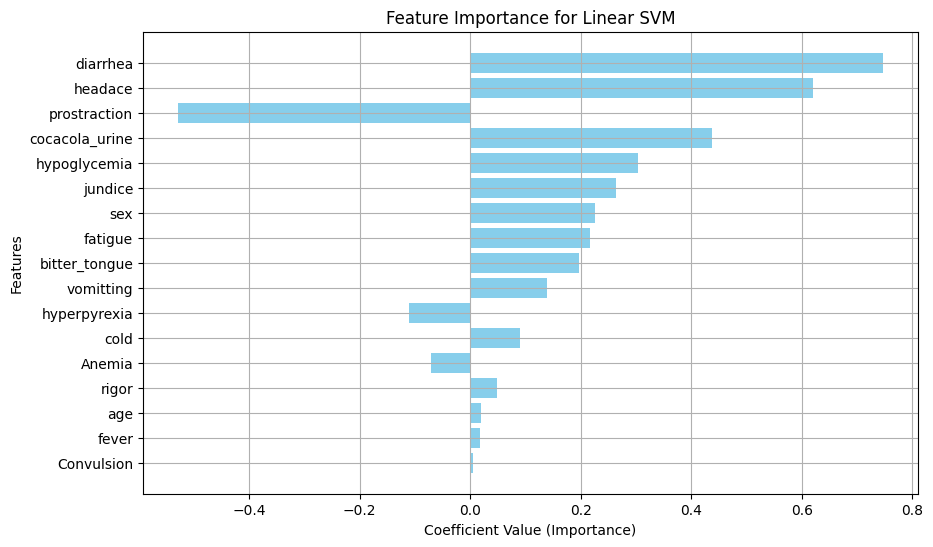

In [29]:
# Plotting feature importance
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_coefficients, color='skyblue')
plt.xlabel('Coefficient Value (Importance)')
plt.ylabel('Features')
plt.title('Feature Importance for Linear SVM')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

## Train the SVM model with an RBF kernel

In [30]:
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train, y_train)

SVC(probability=True, random_state=42)

In [43]:
svm_model.score(X_test, y_test)

y_pred = svm_model.predict(X_test)

from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm


array([[69,  0],
       [33,  0]], dtype=int64)

Accuracy on the test set with best parameters: 0.6765


Text(0.5, 1.0, 'Confusion Matrix for Support Vector Machines')

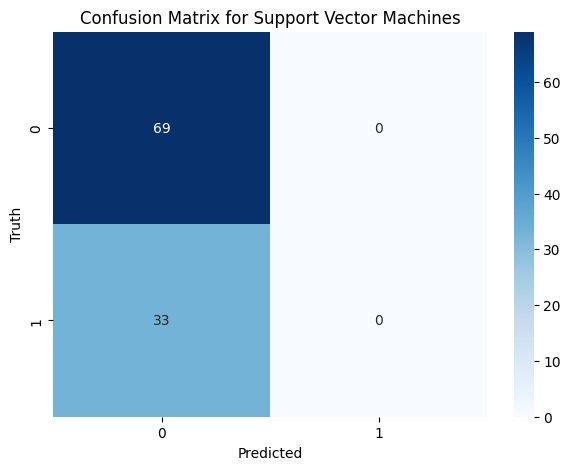

In [44]:
# Evaluate the model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on the test set with best parameters: {accuracy:.4f}")

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize=(7,5))
sn.heatmap(cm, annot=True,fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Truth')
plt.title("Confusion Matrix for Support Vector Machines")


AUC: 0.5050505050505051


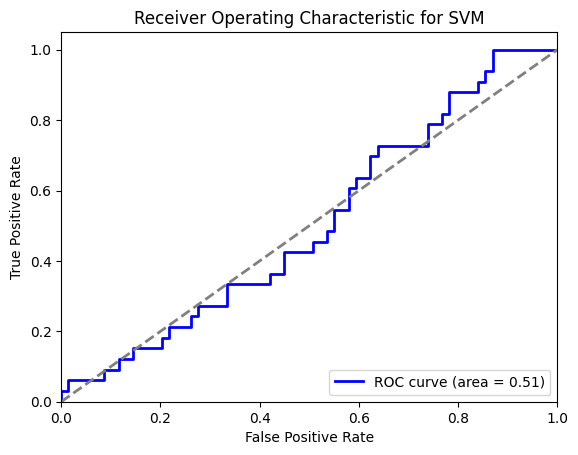

In [45]:
# Predict probabilities
y_pred_prob = svm_model.predict_proba(X_test)[:, 1]

# Compute AUC
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC: {auc}")

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for SVM')
plt.legend(loc="lower right")
plt.show()


In [33]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.contingency_tables import mcnemar


# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Confusion matrix values
TN, FP, FN, TP = cm.ravel()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred)
# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

# Print the results
print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")


Confusion Matrix:
[[69  0]
 [33  0]]
Accuracy: 0.6765
Sensitivity: 0.0000
Specificity: 1.0000
Positive Predictive Value: 0.0000
Negative Predictive Value: 0.6765
F1 Score: 0.0000
Cohen's Kappa: 0.0000
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.0000000
Balanced Accuracy: 0.5000


### Compute permutation importance

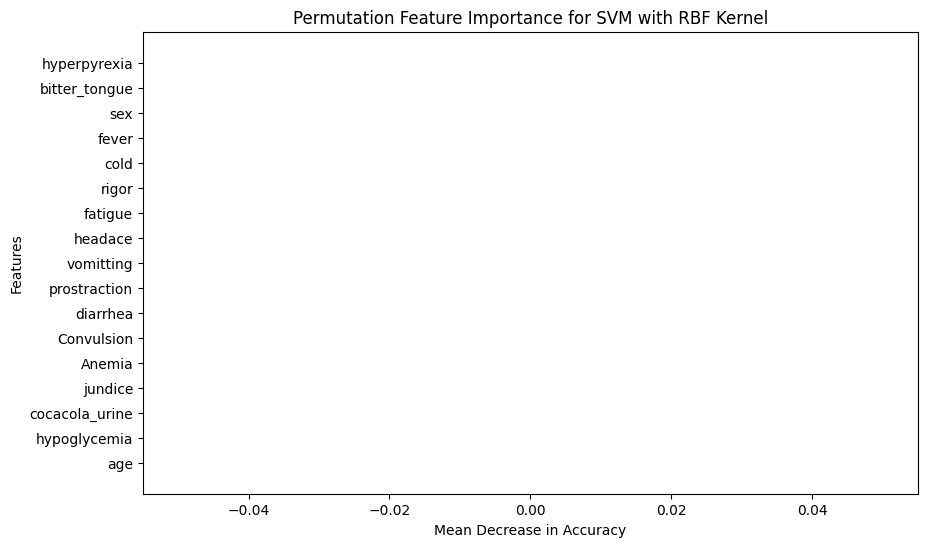

In [34]:
from sklearn.inspection import permutation_importance
result = permutation_importance(svm_model, X_test, y_test, n_repeats=10, random_state=42)

# Compute permutation importance
result = permutation_importance(svm_model, X_test, y_test, n_repeats=10, random_state=42)

# Extract importance and feature names
importance_means = result.importances_mean
sorted_idx = np.argsort(importance_means)[::-1]
sorted_importances = importance_means[sorted_idx]
sorted_features = X.columns[sorted_idx]  # Get the feature names from the DataFrame

# Plot permutation feature importance
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_importances, color='skyblue')
plt.xlabel('Mean Decrease in Accuracy')
plt.ylabel('Features')
plt.title('Permutation Feature Importance for SVM with RBF Kernel')
plt.gca().invert_yaxis()
plt.show()

## Tune parameters
Tuning the parameters for Support Vector Machines (SVM), such as 𝐶 and 𝛾 (gamma), is crucial to achieve the best performance of the model on a given dataset. These parameters control the behavior of the SVM algorithm and can significantly impact the classifier's performance. Here’s a detailed explanation of what these parameters do and how to tune them effectively using cross-validation techniques like GridSearchCV.

## Parameters to Tune

### C (Regularization Parameter):

Description: The 𝐶 parameter controls the trade-off between achieving a low training error and a low testing error (generalization). A smaller 𝐶 value allows the margin to be wider, even if it means some misclassifications on the training data. A larger  𝐶 value aims to classify all training examples correctly, at the risk of overfitting.

Effect: Low 
𝐶-> larger margin but potentially more misclassifications on training data (underfitting). High 
𝐶 -> smaller margin with fewer misclassifications on training data (overfitting).
Gamma (Kernel Coefficient):

Description: The 𝛾 parameter defines how far the influence of a single training example reaches. Low values mean 'far' and high values mean 'close'.
Effect: Low 𝛾-> a model that is too constrained, high bias (underfitting). 
High 𝛾-> a model that is too flexible, high variance (overfitting).

Kernel:

Description: 
The kernel defines the function used to transform the data into a higher-dimensional space. Common kernels include 'linear', 'poly' (polynomial), 'rbf' (radial basis function), and 'sigmoid'.

Effect: Different kernels can capture different types of relationships in the data.
Hyperparameter Tuning Using GridSearchCV
To find the best combination of these parameters, we can use GridSearchCV from scikit-learn. GridSearchCV performs an exhaustive search over specified parameter values for an estimator. It uses cross-validation to evaluate each combination of parameters, ensuring that the selected parameters generalize well to unseen data.

## Note
Gridsearch fail to work due to large number of features

# Random Forest

In [35]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier()
rf_model.fit(X_train,y_train)

RandomForestClassifier()

### Estimate the Random Forest Model

In [36]:
oob_errors = []
rf_model = RandomForestClassifier(n_estimators = 20, oob_score=True, random_state=42)
rf_model.fit(X_train,y_train)

RandomForestClassifier(n_estimators=20, oob_score=True, random_state=42)

### Model's Accuracy

In [37]:
rf_model.score(X_test, y_test)

0.6372549019607843

### Confusion Matrix

In [38]:
from sklearn.metrics import confusion_matrix
y_pred = rf_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
cm

array([[56, 13],
       [24,  9]], dtype=int64)

Text(95.72222222222221, 0.5, 'Truth')

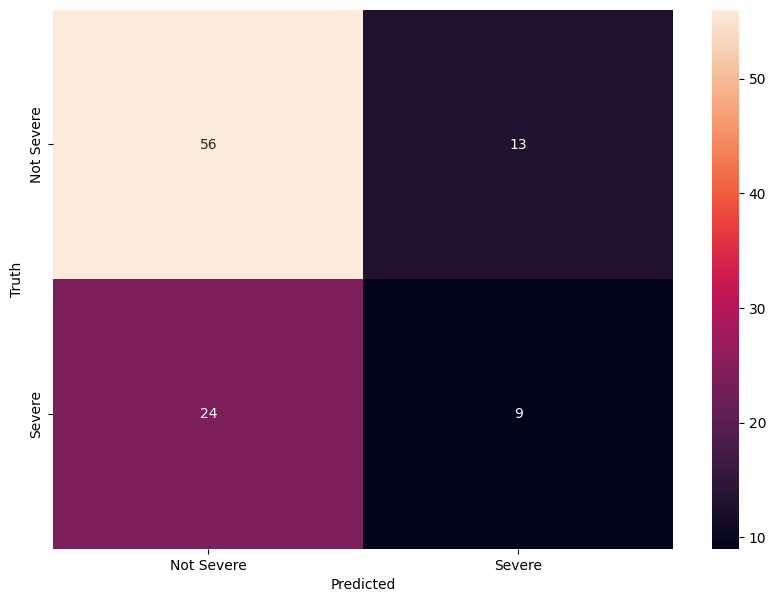

In [39]:
plt.figure(figsize=(10,7))
sns.heatmap(cm, annot=True, xticklabels=["Not Severe", "Severe"], yticklabels=["Not Severe", "Severe"])
plt.xlabel("Predicted")
plt.ylabel("Truth")

In [40]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.contingency_tables import mcnemar


# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Confusion matrix values
TN, FP, FN, TP = cm.ravel()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred)
# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

# Print the results
print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

Confusion Matrix:
[[56 13]
 [24  9]]
Accuracy: 0.6373
Sensitivity: 0.2727
Specificity: 0.8116
Positive Predictive Value: 0.4091
Negative Predictive Value: 0.7000
F1 Score: 0.3273
Cohen's Kappa: 0.0924
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.0988717
Balanced Accuracy: 0.5422


### ROC curve and AUC for Random Forest

AUC: 0.5421607378129119


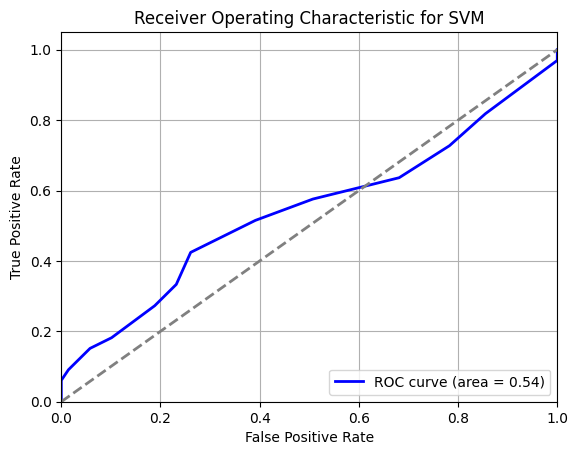

In [41]:
# Predict probabilities
y_pred_prob = rf_model.predict_proba(X_test)[:, 1]

# Compute AUC
auc = roc_auc_score(y_test, y_pred_prob)
print(f"AUC: {auc}")

# Plot ROC curve
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic for SVM')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Features Importance Plot

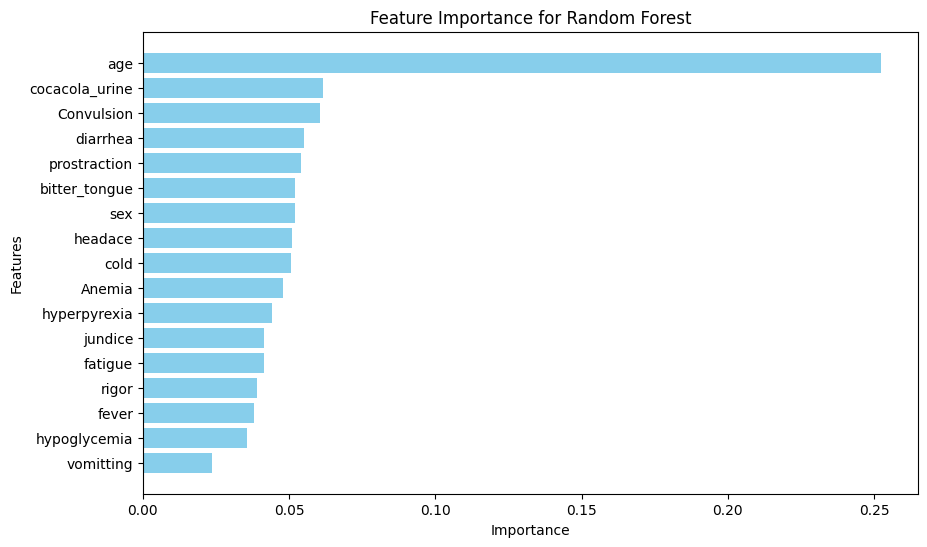

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Get feature importances
importances = rf_model.feature_importances_

# Sort the feature importances in descending order
sorted_idx = np.argsort(importances)[::-1]
sorted_importances = importances[sorted_idx]
sorted_features = X.columns[sorted_idx]

# Plot the feature importance
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_importances, color='skyblue')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Feature Importance for Random Forest')
plt.gca().invert_yaxis()
plt.show()


## Logistic Regression

In [39]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# Train the Logistic Regression model
logreg_model = LogisticRegression(random_state=42)
logreg_model.fit(X_train, y_train)

# Make predictions
y_pred = logreg_model.predict(X_test)

## Evaluate the model

In [40]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.6373
Confusion Matrix:
[[58 11]
 [26  7]]
Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.84      0.76        69
           1       0.39      0.21      0.27        33

    accuracy                           0.64       102
   macro avg       0.54      0.53      0.52       102
weighted avg       0.59      0.64      0.60       102



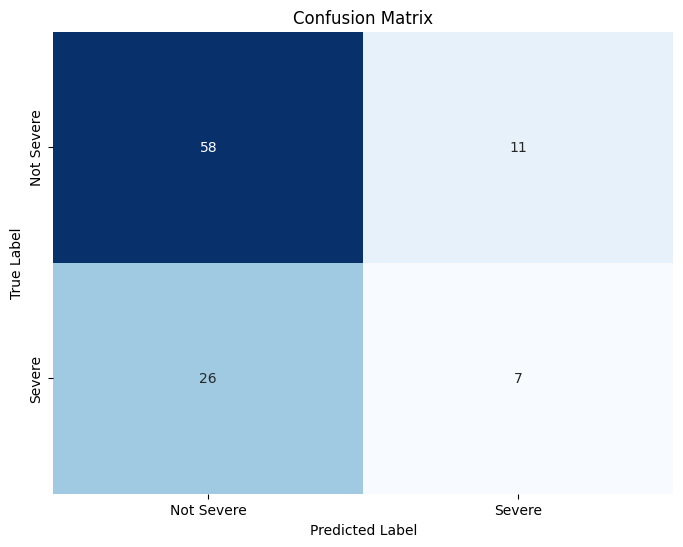

In [41]:
# Confusion Matrix Plot
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=["Not Severe", "Severe"], yticklabels=["Not Severe", "Severe"])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


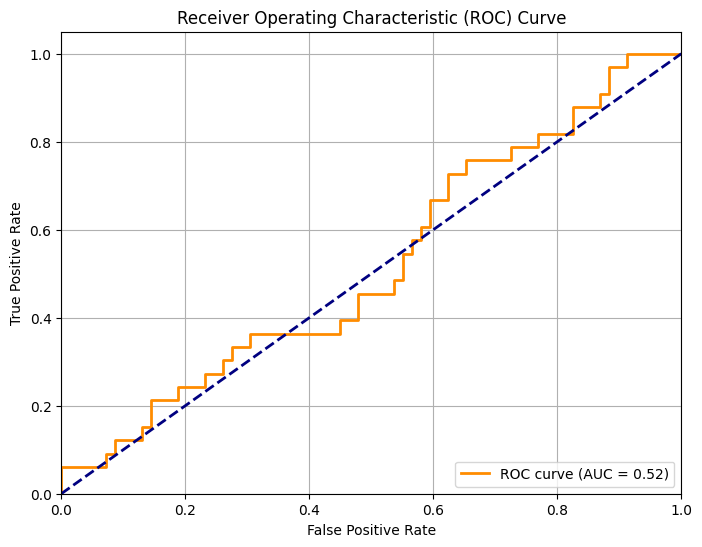

In [42]:
# ROC Curve and AUC
y_prob = logreg_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

### Features Importance Plot

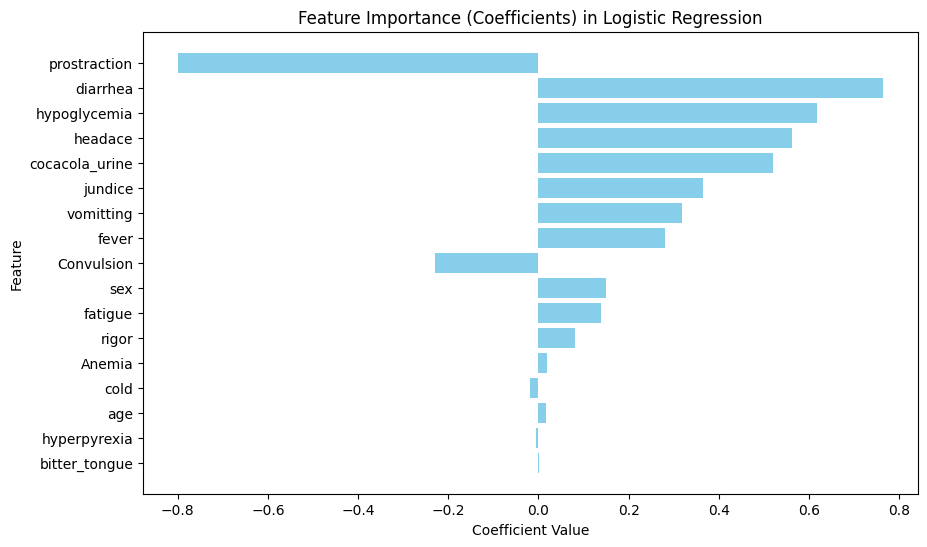

In [43]:
# Get the coefficients and feature names
coefficients = logreg_model.coef_[0]  # Coefficients for the features
features = X.columns  # Feature names

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({'Feature': features, 'Coefficient': coefficients})

# Sort the DataFrame by the absolute value of the coefficients
importance_df['abs_coeff'] = np.abs(importance_df['Coefficient'])
importance_df = importance_df.sort_values(by='abs_coeff', ascending=False)

# Plot the feature importance (coefficients)
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Coefficient'], color='skyblue')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
plt.title('Feature Importance (Coefficients) in Logistic Regression')
plt.gca().invert_yaxis()  # Invert y-axis to have the most important feature at the top
plt.show()

## K-Nearest Neighbors

In [44]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, accuracy_score, confusion_matrix, classification_report
from sklearn.inspection import permutation_importance
import seaborn as sns

# Train the K-Nearest Neighbors model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)

KNeighborsClassifier()

### View the Attributes in the K-NN Model

In [45]:
dir(knn_model)

['__abstractmethods__',
 '__annotations__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__sklearn_clone__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_abc_impl',
 '_build_request_for_signature',
 '_check_algorithm_metric',
 '_check_feature_names',
 '_check_n_features',
 '_doc_link_module',
 '_doc_link_template',
 '_doc_link_url_param_generator',
 '_estimator_type',
 '_fit',
 '_fit_X',
 '_fit_method',
 '_get_default_requests',
 '_get_doc_link',
 '_get_metadata_request',
 '_get_param_names',
 '_get_tags',
 '_kneighbors_reduce_func',
 '_more_tags',
 '_parameter_constraints',
 '_repr_html_',
 '_repr_html_inner',
 '_repr_mimebundle_',
 '_tree',
 '_validate_data',
 '_validate

In [46]:
# Make predictions
y_pred = knn_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.6569
Confusion Matrix:
[[51 18]
 [17 16]]
Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.74      0.74        69
           1       0.47      0.48      0.48        33

    accuracy                           0.66       102
   macro avg       0.61      0.61      0.61       102
weighted avg       0.66      0.66      0.66       102



### Alternatively

In [47]:
print("Logistic Regression Report:")
print(classification_report(y_test, y_pred, target_names=['Not Severe','Severe']))

Logistic Regression Report:
              precision    recall  f1-score   support

  Not Severe       0.75      0.74      0.74        69
      Severe       0.47      0.48      0.48        33

    accuracy                           0.66       102
   macro avg       0.61      0.61      0.61       102
weighted avg       0.66      0.66      0.66       102



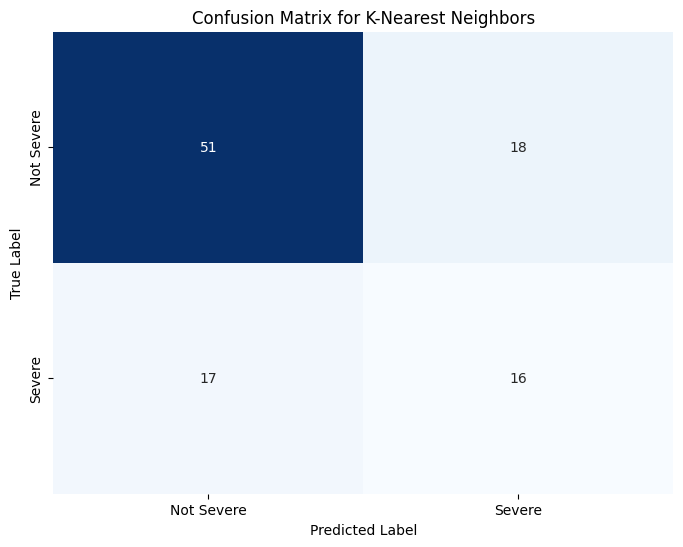

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Generate the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,xticklabels=["Not Severe", "Severe"], yticklabels=["Not Severe", "Severe"])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for K-Nearest Neighbors')
plt.show()


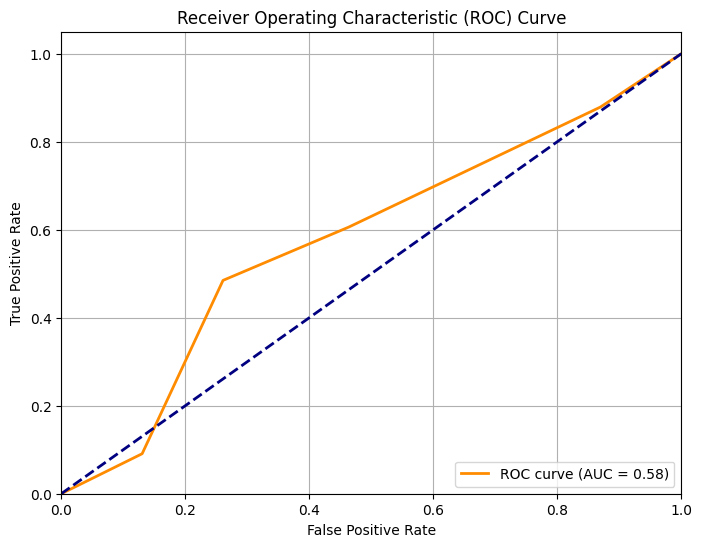

In [49]:
# ROC Curve and AUC
y_prob = knn_model.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


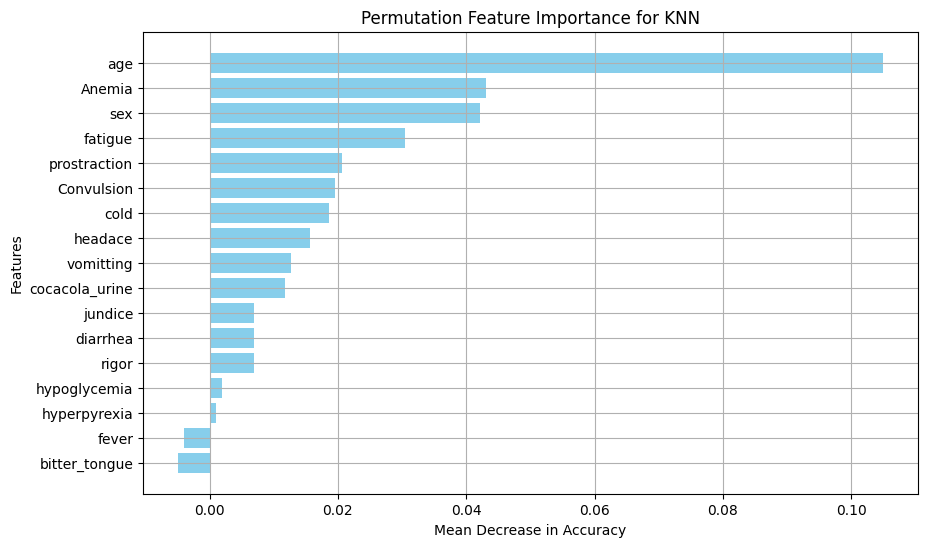

In [50]:
# Permutation Importance
result = permutation_importance(knn_model, X_test, y_test, n_repeats=10, random_state=42)

# Extract importance and feature names
importance_means = result.importances_mean
sorted_idx = np.argsort(importance_means)[::-1]
sorted_importances = importance_means[sorted_idx]
sorted_features = X.columns[sorted_idx]

# Plot permutation feature importance
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_importances, color='skyblue')
plt.xlabel('Mean Decrease in Accuracy')
plt.ylabel('Features')
plt.title('Permutation Feature Importance for KNN')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()


### Artificial Neural Network (ANN)

In [51]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
# Create the ANN model
ann = Sequential()
ann.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
ann.add(Dense(16, activation='relu'))
ann.add(Dense(1, activation='sigmoid'))

In [52]:
# Compile the model
ann.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
ann.fit(X_train, y_train, epochs=100, batch_size=10, validation_split=0.2)


Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6117 - loss: 0.6622 - val_accuracy: 0.6596 - val_loss: 0.6487
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5832 - loss: 0.6766 - val_accuracy: 0.7660 - val_loss: 0.5999
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6081 - loss: 0.6647 - val_accuracy: 0.7447 - val_loss: 0.6176
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5812 - loss: 0.6986 - val_accuracy: 0.7660 - val_loss: 0.5967
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5882 - loss: 0.6741 - val_accuracy: 0.6596 - val_loss: 0.6436
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6604 - loss: 0.6618 - val_accuracy: 0.7660 - val_loss: 0.5863
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6063 - loss: 0.6888 - val_accuracy: 0.7660 - val_loss: 0.6074
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5957 - loss: 0.6722 - val_accuracy: 0.7872 - 

In [53]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import plot_model

# Plot the model architecture
plot_model(ann, to_file='neural_network.png', show_shapes=True, show_layer_names=True)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


In [54]:
# Make predictions
y_pred_ann = (ann.predict(X_test) > 0.5).astype("int32")

# Evaluate the model
print("Artificial Neural Networks Report:")
classification_report(y_test, y_pred_ann, target_names=['no', 'yes'], output_dict=True)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Artificial Neural Networks Report:


{'no': {'precision': 0.7076923076923077,
  'recall': 0.6666666666666666,
  'f1-score': 0.6865671641791045,
  'support': 69.0},
 'yes': {'precision': 0.3783783783783784,
  'recall': 0.42424242424242425,
  'f1-score': 0.4,
  'support': 33.0},
 'accuracy': 0.5882352941176471,
 'macro avg': {'precision': 0.5430353430353431,
  'recall': 0.5454545454545454,
  'f1-score': 0.5432835820895523,
  'support': 102.0},
 'weighted avg': {'precision': 0.6011495658554482,
  'recall': 0.5882352941176471,
  'f1-score': 0.5938542581211589,
  'support': 102.0}}

In [55]:
import pandas as pd
from sklearn.metrics import classification_report
report = classification_report(y_test, y_pred_ann, target_names=['Not severe', 'Severe'], output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df

,precision,recall,f1-score,support
Not severe,0.707692,0.666667,0.686567,69.000000
Severe,0.378378,0.424242,0.400000,33.000000
accuracy,0.588235,0.588235,0.588235,0.588235
macro avg,0.543035,0.545455,0.543284,102.000000
weighted avg,0.601150,0.588235,0.593854,102.000000


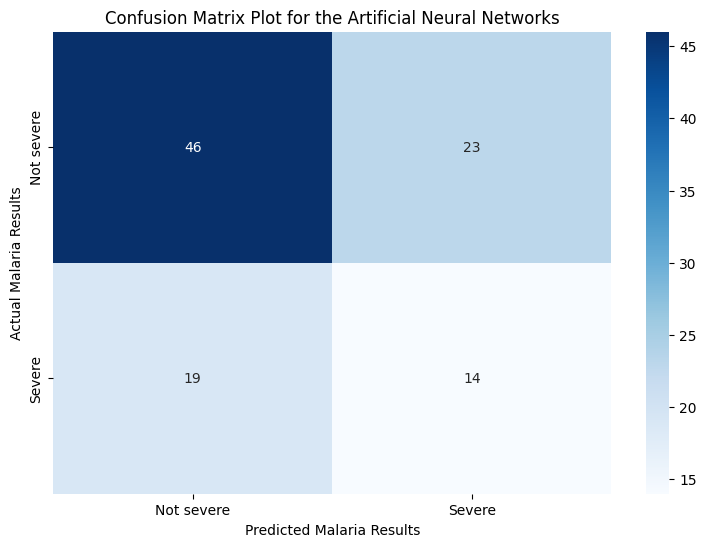

In [56]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.contingency_tables import mcnemar

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_ann)
cm
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
plt.xlabel('Predicted Malaria Results')
plt.ylabel('Actual Malaria Results')
plt.title('Confusion Matrix Plot for the Artificial Neural Networks')
plt.show()


In [57]:
TN, FP, FN, TP = cm.ravel()
# Accuracy
accuracy = accuracy_score(y_test, y_pred_ann)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred_ann)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred_ann)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred_ann)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred_ann)

# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

Confusion Matrix:
[[46 23]
 [19 14]]
Accuracy: 0.5882
Sensitivity: 0.4242
Specificity: 0.6667
Positive Predictive Value: 0.3784
Negative Predictive Value: 0.7077
F1 Score: 0.4000
Cohen's Kappa: 0.0881
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.6439690
Balanced Accuracy: 0.5455


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
AUC-ROC: 0.62


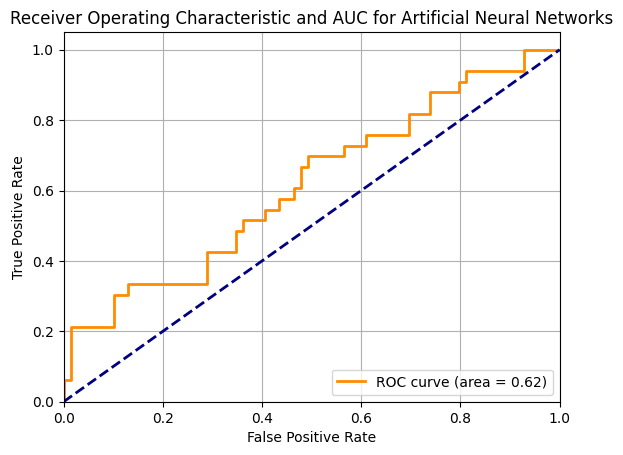

In [58]:
## Predict decision function scores for ROC
y_scores = ann.predict(X_test)

from sklearn.linear_model import RidgeClassifier
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
import matplotlib.pyplot as plt
# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

print(f"AUC-ROC: {roc_auc:.2f}")

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic and AUC for Artificial Neural Networks')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [59]:
history = ann.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, batch_size=32)

# Accessing the loss function value for the final epoch
final_loss = history.history['loss'][-1]

# Accessing the loss function value for the validation set (if applicable)
final_test_loss = history.history['val_loss'][-1]

print(f"Final Training Loss: {final_loss}")
print(f"Final Testing Loss: {final_test_loss}")

Epoch 1/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7258 - loss: 0.5906 - val_accuracy: 0.6471 - val_loss: 0.6232
Epoch 2/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7231 - loss: 0.5602 - val_accuracy: 0.7059 - val_loss: 0.6264
Epoch 3/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6958 - loss: 0.5980 - val_accuracy: 0.6078 - val_loss: 0.6420
Epoch 4/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7164 - loss: 0.5558 - val_accuracy: 0.6863 - val_loss: 0.6175
Epoch 5/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6742 - loss: 0.5897 - val_accuracy: 0.6961 - val_loss: 0.6169
Epoch 6/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7070 - loss: 0.5690 - val_accuracy: 0.7059 - val_loss: 0.6174
Epoch 7/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7070 - loss: 0.5847 - val_accuracy: 0.6667 - val_loss: 0.6206
Epoch 8/10
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6879 - loss: 0.5875 - val_accuracy: 0.7059 - val_loss: 0.6188
Ep

### Naive Bayes (NB)

In [60]:
from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import ComplementNB
from sklearn.naive_bayes import BernoulliNB
from sklearn.naive_bayes import CategoricalNB

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB, ComplementNB, CategoricalNB

# Gaussian Naive Bayes
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_gnb = gnb.predict(X_test)
print("GaussianNB Accuracy:", accuracy_score(y_test, y_pred_gnb))
accuracy_gnb = accuracy_score(y_test, y_pred_gnb)

GaussianNB Accuracy: 0.5294117647058824


In [61]:
# Multinomial Naive Bayes
mnb = MultinomialNB()
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)
print("MultinomialNB Accuracy:", accuracy_score(y_test, y_pred_mnb))
accuracy_mnb = accuracy_score(y_test, y_pred_mnb)

MultinomialNB Accuracy: 0.6764705882352942


In [62]:
# Bernoulli Naive Bayes
bnb = BernoulliNB()
bnb.fit(X_train, y_train)
y_pred_bnb = bnb.predict(X_test)
print("BernoulliNB Accuracy:", accuracy_score(y_test, y_pred_bnb))
accuracy_bnb = accuracy_score(y_test, y_pred_bnb)

BernoulliNB Accuracy: 0.5882352941176471


In [63]:
# Complement Naive Bayes 
cnb = ComplementNB()
cnb.fit(X_train, y_train)
y_pred_cnb = cnb.predict(X_test)
print("ComplementNB Accuracy:", accuracy_score(y_test, y_pred_cnb))
accuracy_cnb = accuracy_score(y_test, y_pred_cnb)

ComplementNB Accuracy: 0.5


In [64]:
catnb = CategoricalNB()
catnb.fit(X_train, y_train)
y_pred_catnb = catnb.predict(X_test)
print("CategoricalNB Accuracy:", accuracy_score(y_test, y_pred_catnb))
accuracy_catnb = accuracy_score(y_test, y_pred_catnb)

CategoricalNB Accuracy: 0.6176470588235294


In [65]:
# Create a DataFrame to store the results
data = {
    'Naive Bayes Type': ['GaussianNB', 'MultinomialNB', 'BernoulliNB', 'ComplementNB', 'CategoricalNB'],
    'Classification Accuracy': [accuracy_gnb, accuracy_mnb, accuracy_bnb, accuracy_cnb, accuracy_catnb]
}
df_results = pd.DataFrame(data)
df_results


,Naive Bayes Type,Classification Accuracy
0,GaussianNB,0.529412
1,MultinomialNB,0.676471
2,BernoulliNB,0.588235
3,ComplementNB,0.500000
4,CategoricalNB,0.617647


In [66]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

accuracy = accuracy_score(y_test, y_pred_gnb)
conf_matrix = confusion_matrix(y_test, y_pred_gnb)
class_report = classification_report(y_test, y_pred_gnb, target_names = ["Not severe","Severe"])

print(f"Accuracy: {accuracy:.2f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)


Accuracy: 0.53
Confusion Matrix:
[[42 27]
 [21 12]]
Classification Report:
              precision    recall  f1-score   support

  Not severe       0.67      0.61      0.64        69
      Severe       0.31      0.36      0.33        33

    accuracy                           0.53       102
   macro avg       0.49      0.49      0.48       102
weighted avg       0.55      0.53      0.54       102



### ROC and AUC for Naive Bayes

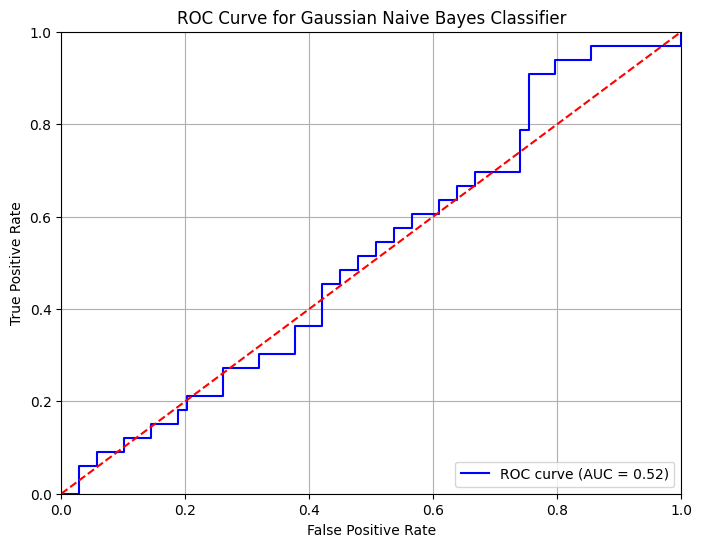

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split

# Predict probabilities
y_prob = gnb.predict_proba(X_test)[:, 1]  # Get the probabilities for the positive class

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', label=f'ROC curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Gaussian Naive Bayes Classifier')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


### Features Importance Plot

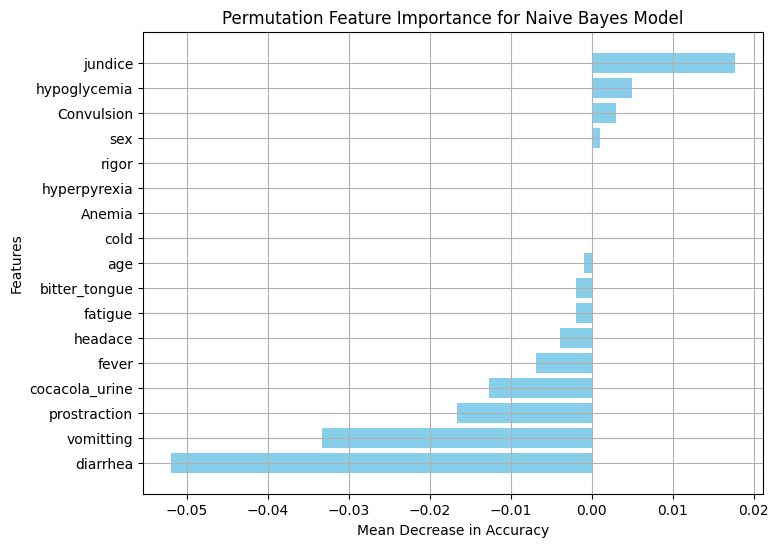

In [68]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import numpy as np

# Assuming the Naive Bayes model (nb_model) is already trained and X_test, y_test are defined

# Calculate permutation importance
result = permutation_importance(gnb, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')

# Extract importance and feature names
importance_means = result.importances_mean
sorted_idx = np.argsort(importance_means)[::-1]
sorted_importances = importance_means[sorted_idx]
sorted_features = X.columns[sorted_idx]  # Assuming X is a DataFrame with feature names

# Plot permutation feature importance
plt.figure(figsize=(8, 6))
plt.barh(sorted_features, sorted_importances, color='skyblue')
plt.xlabel('Mean Decrease in Accuracy')
plt.ylabel('Features')
plt.title('Permutation Feature Importance for Naive Bayes Model')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()


### Linear Discriminant Analysis

In [69]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np
# Train LDA model
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, y_train)

LinearDiscriminantAnalysis()

In [70]:
# Predict probabilities for ROC and AUC calculation
y_prob_lda = lda_model.predict_proba(X_test)[:, 1]  # Probabilities for the positive class

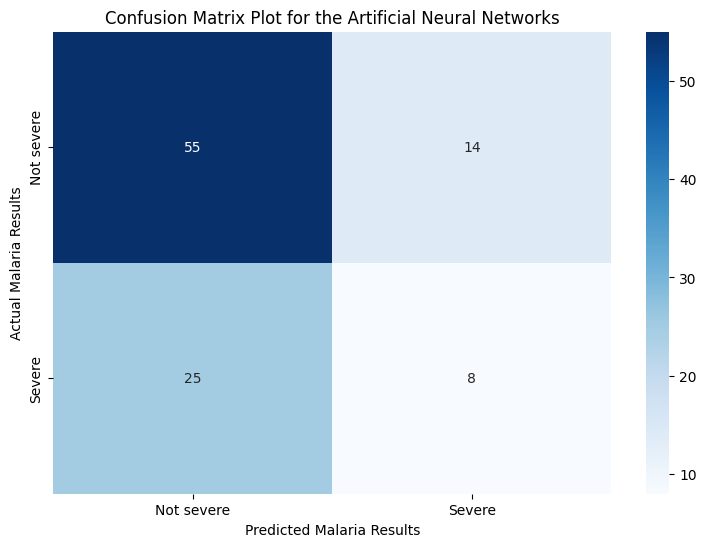

In [71]:
# Confusion matrix
y_pred_lda = lda_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_lda)
cm
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
plt.xlabel('Predicted Malaria Results')
plt.ylabel('Actual Malaria Results')
plt.title('Confusion Matrix Plot for the Artificial Neural Networks')
plt.show()

In [72]:
print("Logistic Regression Report:")
print(classification_report(y_test, y_pred_lda, target_names=['Not Severe','Severe']))

Logistic Regression Report:
              precision    recall  f1-score   support

  Not Severe       0.69      0.80      0.74        69
      Severe       0.36      0.24      0.29        33

    accuracy                           0.62       102
   macro avg       0.53      0.52      0.51       102
weighted avg       0.58      0.62      0.59       102



### Obtain Other Performance Metrics

In [73]:
TN, FP, FN, TP = cm.ravel()
# Accuracy
accuracy = accuracy_score(y_test, y_pred_lda)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred_lda)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred_lda)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred_lda)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred_lda)

# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

Confusion Matrix:
[[55 14]
 [25  8]]
Accuracy: 0.6176
Sensitivity: 0.2424
Specificity: 0.7971
Positive Predictive Value: 0.3636
Negative Predictive Value: 0.6875
F1 Score: 0.2909
Cohen's Kappa: 0.0433
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.1081290
Balanced Accuracy: 0.5198


### Plot ROC curve for LDA

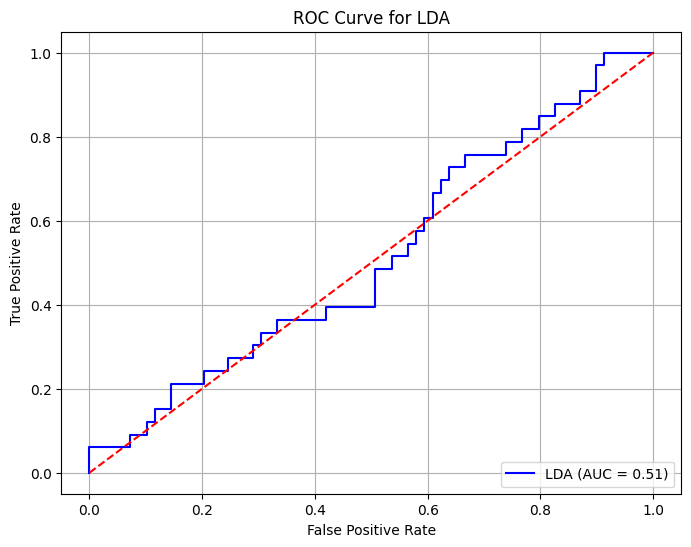

In [74]:
# Calculate ROC curve and AUC for LDA
fpr_lda, tpr_lda, _ = roc_curve(y_test, y_prob_lda)
auc_score_lda = roc_auc_score(y_test, y_prob_lda)
plt.figure(figsize=(8, 6))
plt.plot(fpr_lda, tpr_lda, label=f'LDA (AUC = {auc_score_lda:.2f})', color='blue')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for LDA')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

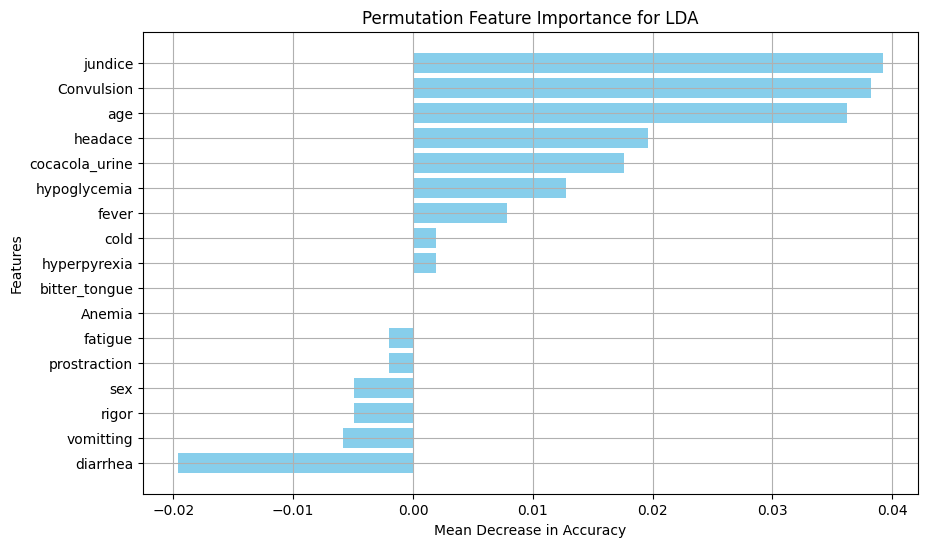

In [75]:
# Feature Importance for LDA using Permutation Importance
from sklearn.inspection import permutation_importance

result_lda = permutation_importance(lda_model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')
importance_means_lda = result_lda.importances_mean
sorted_idx_lda = np.argsort(importance_means_lda)[::-1]
sorted_importances_lda = importance_means_lda[sorted_idx_lda]
sorted_features_lda = X.columns[sorted_idx_lda]

plt.figure(figsize=(10, 6))
plt.barh(sorted_features_lda, sorted_importances_lda, color='skyblue')
plt.xlabel('Mean Decrease in Accuracy')
plt.ylabel('Features')
plt.title('Permutation Feature Importance for LDA')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

### Quadratic Discriminant Analysis

In [76]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

# Train QDA model
qda_model = QuadraticDiscriminantAnalysis()
qda_model.fit(X_train, y_train)

QuadraticDiscriminantAnalysis()

In [77]:
# Predict probabilities for ROC and AUC calculation
y_prob_qda = qda_model.predict_proba(X_test)[:, 1]  # Probabilities for the positive class

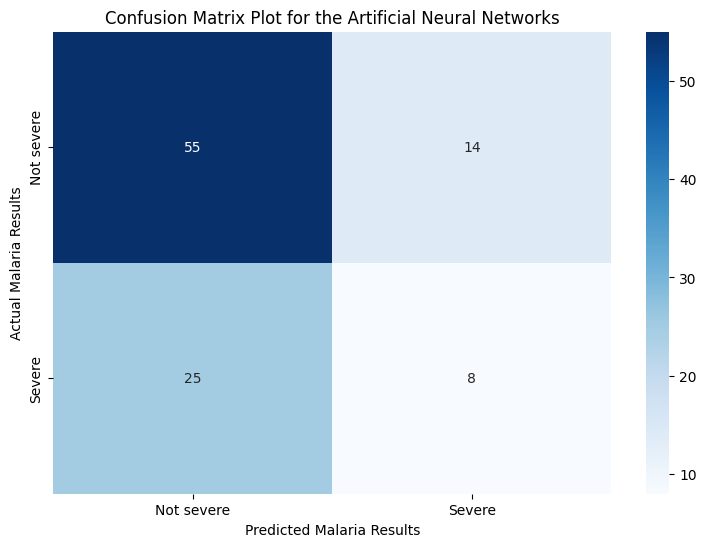

In [78]:
# Confusion matrix
y_pred_qda = lda_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_qda)
cm
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
plt.xlabel('Predicted Malaria Results')
plt.ylabel('Actual Malaria Results')
plt.title('Confusion Matrix Plot for the Artificial Neural Networks')
plt.show()

In [79]:
print("Logistic Regression Report:")
print(classification_report(y_test, y_pred_qda, target_names=['Not Severe','Severe']))


Logistic Regression Report:
              precision    recall  f1-score   support

  Not Severe       0.69      0.80      0.74        69
      Severe       0.36      0.24      0.29        33

    accuracy                           0.62       102
   macro avg       0.53      0.52      0.51       102
weighted avg       0.58      0.62      0.59       102



### Obtain other Performance Metrics

In [80]:
TN, FP, FN, TP = cm.ravel()
# Accuracy
accuracy = accuracy_score(y_test, y_pred_qda)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred_qda)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred_qda)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred_qda)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred_qda)

# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")


Confusion Matrix:
[[55 14]
 [25  8]]
Accuracy: 0.6176
Sensitivity: 0.2424
Specificity: 0.7971
Positive Predictive Value: 0.3636
Negative Predictive Value: 0.6875
F1 Score: 0.2909
Cohen's Kappa: 0.0433
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.1081290
Balanced Accuracy: 0.5198


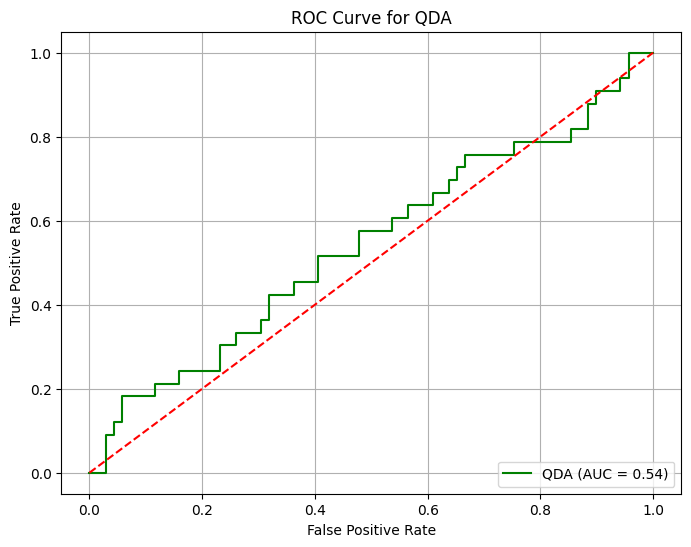

In [81]:
# Calculate ROC curve and AUC for QDA
fpr_qda, tpr_qda, _ = roc_curve(y_test, y_prob_qda)
auc_score_qda = roc_auc_score(y_test, y_prob_qda)

# Plot ROC curve for QDA
plt.figure(figsize=(8, 6))
plt.plot(fpr_qda, tpr_qda, label=f'QDA (AUC = {auc_score_qda:.2f})', color='green')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for QDA')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

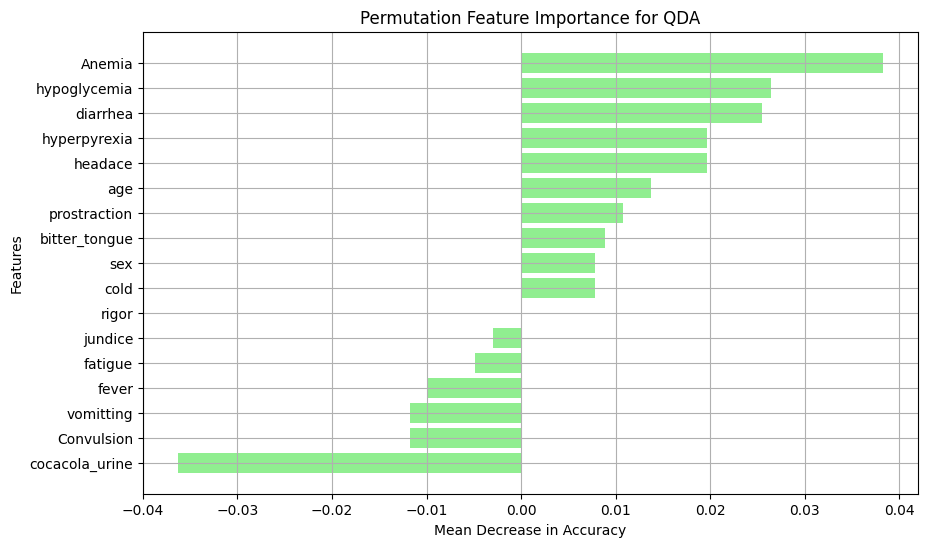

In [82]:

# Feature Importance for QDA using Permutation Importance
result_qda = permutation_importance(qda_model, X_test, y_test, n_repeats=10, random_state=42, scoring='accuracy')
importance_means_qda = result_qda.importances_mean
sorted_idx_qda = np.argsort(importance_means_qda)[::-1]
sorted_importances_qda = importance_means_qda[sorted_idx_qda]
sorted_features_qda = X.columns[sorted_idx_qda]

plt.figure(figsize=(10, 6))
plt.barh(sorted_features_qda, sorted_importances_qda, color='lightgreen')
plt.xlabel('Mean Decrease in Accuracy')
plt.ylabel('Features')
plt.title('Permutation Feature Importance for QDA')
plt.gca().invert_yaxis()
plt.grid(True)
plt.show()

### Tree Bagging 
For bagging we need to set the parameter n_estimators, this is the number of base classifiers that our model is going to aggregate together.

For this sample dataset the number of estimators is relatively low, it is often the case that much larger ranges are explored. Hyperparameter tuning is usually done with a grid search, but for now we will use a select set of values for the number of estimator.

We start by importing the necessary model.

In [83]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

Now lets create a range of values that represent the number of estimators we want to use in each ensemble.

In [84]:
estimator_range = [2,4,6,8,10,12,14,16]

To see how the Bagging Classifier performs with differing values of n_estimators we need a way to iterate over the range of values and store the results from each ensemble. To do this we will create a for loop, storing the models and scores in separate lists for later vizualizations.

### Note: 
The default parameter for the base classifier in BaggingClassifier is the DicisionTreeClassifier therefore we do not need to set it when instantiating the bagging model.

In [85]:
models = []
scores = []

for n_estimators in estimator_range:
    
    # Create bagging classifier
    clf = BaggingClassifier(n_estimators = n_estimators, random_state = 22)

    # Fit the model
    clf.fit(X_train, y_train)

    # Append the model and score to their respective list
    models.append(clf)
    scores.append(accuracy_score(y_true = y_test, y_pred = clf.predict(X_test)))

With the models and scores stored, we can now visualize the improvement in model performance.

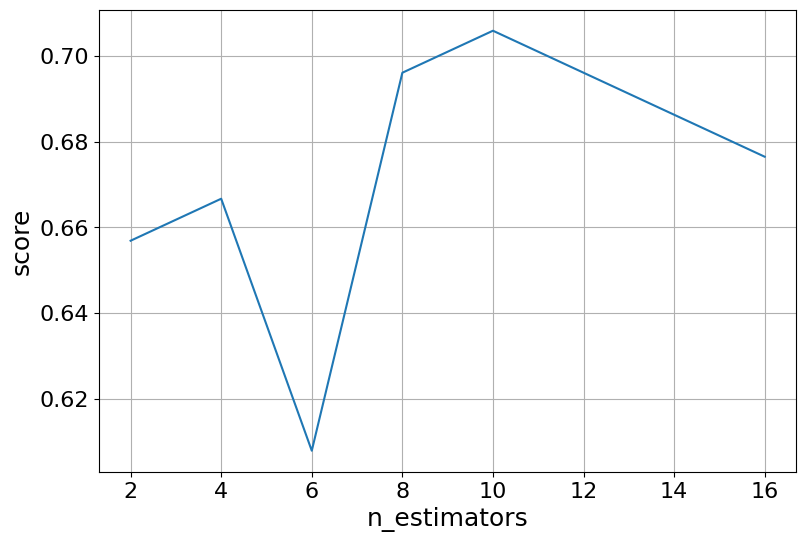

In [86]:
import matplotlib.pyplot as plt

# Generate the plot of scores against number of estimators
plt.figure(figsize=(9,6))
plt.plot(estimator_range, scores)

# Adjust labels and font (to make visable)
plt.xlabel("n_estimators", fontsize = 18)
plt.ylabel("score", fontsize = 18)
plt.tick_params(labelsize = 16)

# Visualize plot
plt.grid(True)
plt.show()

By iterating through different values for the number of estimators, we can see an increase in model performance from 61.2% to about 72.5%. After 10 estimators the accuracy begins to drop, again if you set a different random_state the values you see will vary. That is why it is best practice to use cross validation to ensure stable results.e.

### Generating Decision Trees from Bagging Classifier
As was seen in the Decision Tree lesson, it is possible to graph the decision tree the model created. It is also possible to see the individual decision trees that went into the aggregated classifier. This helps us to gain a more intuitive understanding on how the bagging model arrives at its prediction.

### Note
e: This is only functional with smaller datasets, where the trees are relatively shallow and nar,row making them easy to visuali .

We will need to import plot_tree function from sklearn.tree. The different trees can be graphed by changing the estimator you wish to visualize.

## Ada Boost
AdaBoost (Adaptive Boosting) is a powerful ensemble learning method that combines multiple weak learners, typically decision trees, to create a strong classifier. The idea behind AdaBoost is to sequentially train weak learners, with each one focusing more on the instances that previous learners misclassified. This adaptive nature allows AdaBoost to improve accuracy by emphasizing difficult cases.

Here’s how you can implement an AdaBoost model in Python using the AdaBoostClassifier from the sklearn library:

In [87]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score
import matplotlib.pyplot as plt


# Initialize AdaBoost with Decision Trees as the base estimator
ada_model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=42)
ada_model.fit(X_train, y_train)
ada_model

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                   random_state=42)

In [88]:
# Make predictions
y_pred_ada = ada_model.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred_ada)
print(f'Accuracy: {accuracy:.4f}')

Accuracy: 0.5980


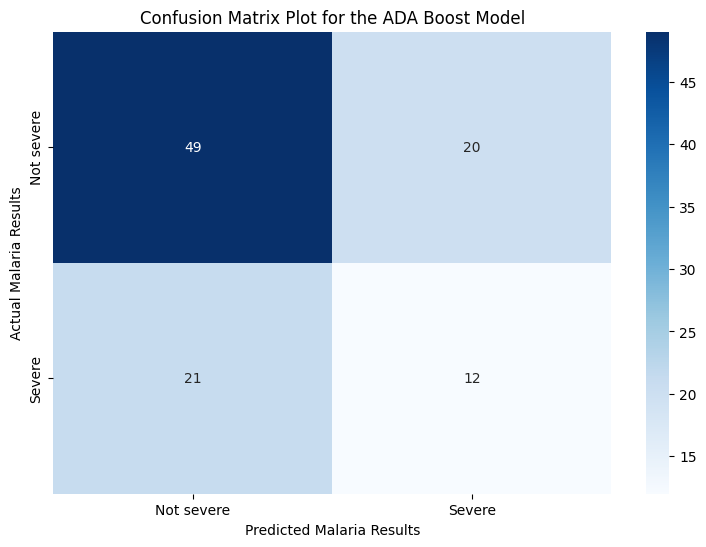

In [89]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_ada)
cm
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import pandas as pd
import numpy as np

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Not severe", "Severe"], yticklabels=["Not severe", "Severe"])
plt.xlabel('Predicted Malaria Results')
plt.ylabel('Actual Malaria Results')
plt.title('Confusion Matrix Plot for the ADA Boost Model')
plt.show()

In [90]:
# Calculate ROC-AUC
y_prob = ada_model.predict_proba(X_test)[:, 1]  # Probability of the positive class
auc_score = roc_auc_score(y_test, y_prob)
print(f'ROC-AUC: {auc_score:.4f}')

ROC-AUC: 0.5296


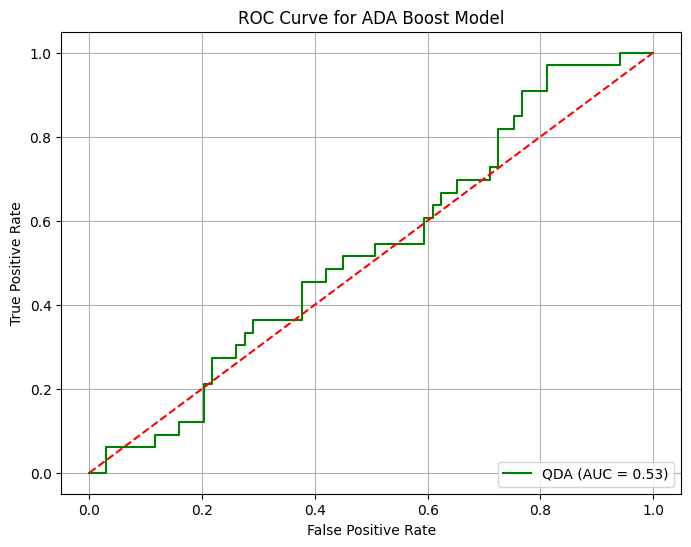

In [91]:
# Calculate ROC curve and AUC for QDA
fpr_ada, tpr_ada, _ = roc_curve(y_test, y_prob)
auc_score_ada = roc_auc_score(y_test, y_prob)

# Plot ROC curve for QDA
plt.figure(figsize=(8, 6))
plt.plot(fpr_ada, tpr_ada, label=f'QDA (AUC = {auc_score_ada:.2f})', color='green')
plt.plot([0, 1], [0, 1], color='red', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for ADA Boost Model')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

### Feature Importance Plot

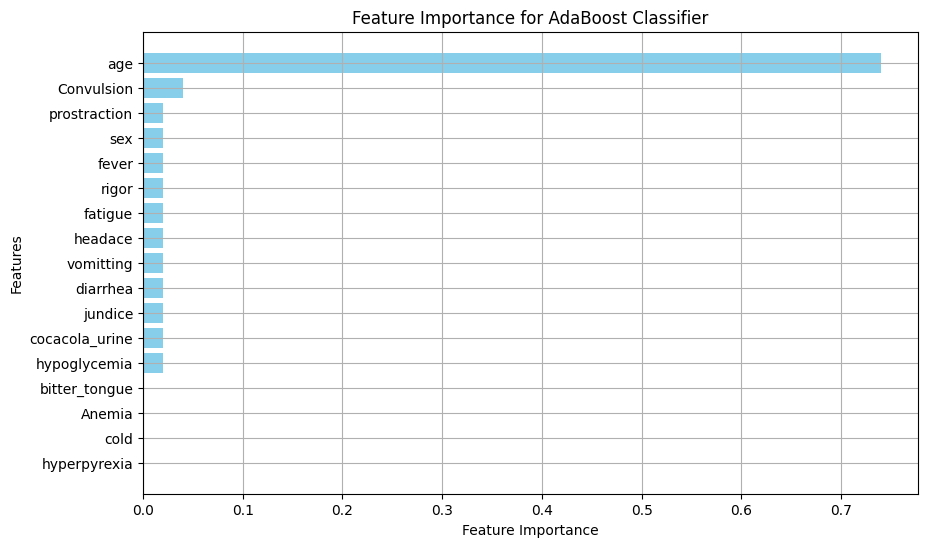

In [92]:
import numpy as np
import matplotlib.pyplot as plt

# Assuming ada_model is the trained AdaBoostClassifier
# and X_train is the DataFrame or array with feature names

# Extract feature importances
importances = ada_model.feature_importances_

# Sort feature importances in descending order
sorted_idx = np.argsort(importances)[::-1]
sorted_importances = importances[sorted_idx]
sorted_features = X_train.columns[sorted_idx]  # Assuming X_train is a DataFrame with feature names

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.barh(sorted_features, sorted_importances, color='skyblue')
plt.xlabel('Feature Importance')
plt.ylabel('Features')
plt.title('Feature Importance for AdaBoost Classifier')
plt.gca().invert_yaxis()  # Invert y-axis to have the highest importance at the top
plt.grid(True)
plt.show()

## Extreme Gradient Boosting (XGBoost)

In [93]:
import xgboost as xgb
# Create and train the XGBoost model
xgb_model = xgb.XGBClassifier()
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate the model
print("Extreme Gradient Boosting Report:")
report = classification_report(y_test, y_pred_xgb, target_names=['Not severe', 'Severe'], output_dict=True)
report_df = pd.DataFrame(report).transpose()
report_df


Extreme Gradient Boosting Report:


,precision,recall,f1-score,support
Not severe,0.708333,0.739130,0.723404,69.000000
Severe,0.400000,0.363636,0.380952,33.000000
accuracy,0.617647,0.617647,0.617647,0.617647
macro avg,0.554167,0.551383,0.552178,102.000000
weighted avg,0.608578,0.617647,0.612611,102.000000


In [94]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, cohen_kappa_score, roc_auc_score
from sklearn.model_selection import train_test_split
from statsmodels.stats.contingency_tables import mcnemar

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_xgb)
cm

array([[51, 18],
       [21, 12]], dtype=int64)

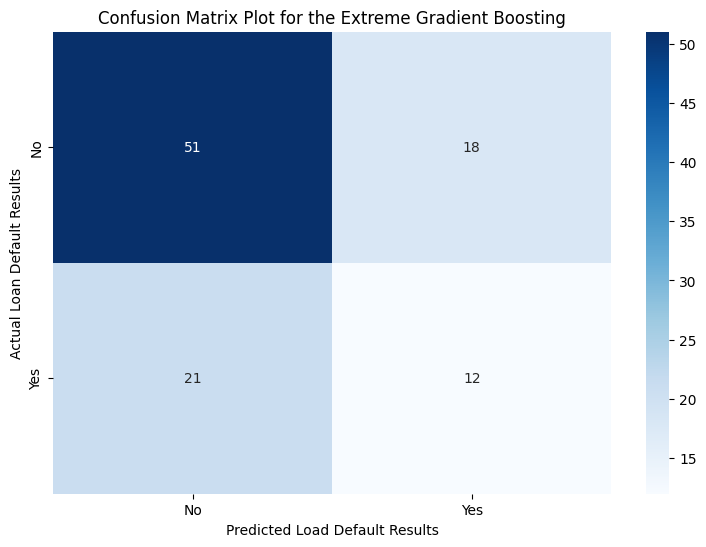

Confusion Matrix:
[[51 18]
 [21 12]]
Accuracy: 0.6176
Sensitivity: 0.3636
Specificity: 0.7391
Positive Predictive Value: 0.4000
Negative Predictive Value: 0.7083
F1 Score: 0.3810
Cohen's Kappa: 0.1053
No Information Rate (NIR): 0.6765
McNemar's Test P-Value: 0.7492586
Balanced Accuracy: 0.5514


In [95]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel('Predicted Load Default Results')
plt.ylabel('Actual Loan Default Results')
plt.title('Confusion Matrix Plot for the Extreme Gradient Boosting')
plt.show()

TN, FP, FN, TP = cm.ravel()
# Accuracy
accuracy = accuracy_score(y_test, y_pred_xgb)

# Sensitivity (Recall)
sensitivity = recall_score(y_test, y_pred_xgb)

# Specificity
specificity = TN / (TN + FP)

# Positive Predictive Value (Precision)
ppv = precision_score(y_test, y_pred_xgb)

# Negative Predictive Value
npv = TN / (TN + FN)

# F1 Score
f1 = f1_score(y_test, y_pred_xgb)

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred_xgb)

# No Information Rate (NIR)
nir = y_test.value_counts().max() / len(y_test)

# McNemar's Test P-Value
mcnemar_result = mcnemar(cm)
mcnemar_p_value = mcnemar_result.pvalue

# Balanced Accuracy
balanced_accuracy = (sensitivity + specificity) / 2

print(f"Confusion Matrix:\n{cm}")
print(f"Accuracy: {accuracy:.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Positive Predictive Value: {ppv:.4f}")
print(f"Negative Predictive Value: {npv:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Cohen's Kappa: {kappa:.4f}")
print(f"No Information Rate (NIR): {nir:.4f}")
#print(f"P-Value [Acc > NIR]: {p_value_acc_nir:.7f}")
print(f"McNemar's Test P-Value: {mcnemar_p_value:.7f}")
print(f"Balanced Accuracy: {balanced_accuracy:.4f}")

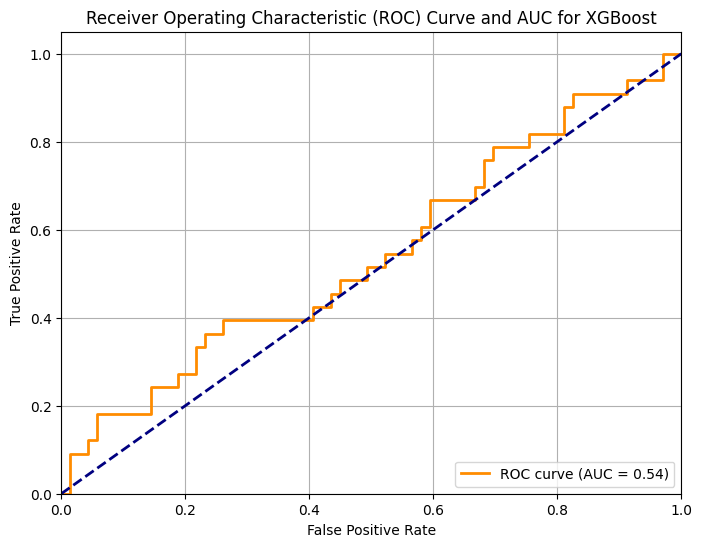

AUC: 0.54


In [96]:
# Get prediction probabilities for the positive class
y_scores = xgb_model.predict_proba(X_test)[:, 1]

# Compute ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve and AUC for XGBoost')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# Print AUC score
print(f'AUC: {roc_auc:.2f}')


### Plot the ROC and AUC Curves in one Plot
* Support Vector Machines (SVM): svm_model
* Naive Bayes: mnb
* K-Nearest Neighbots (k-NN): knn_model
* Artificial Neural Network: ann
* Random Forest (RF): rf_model
* ADA Boost Model: ada_model
* Extreme Gradient Boosting: xgb_model

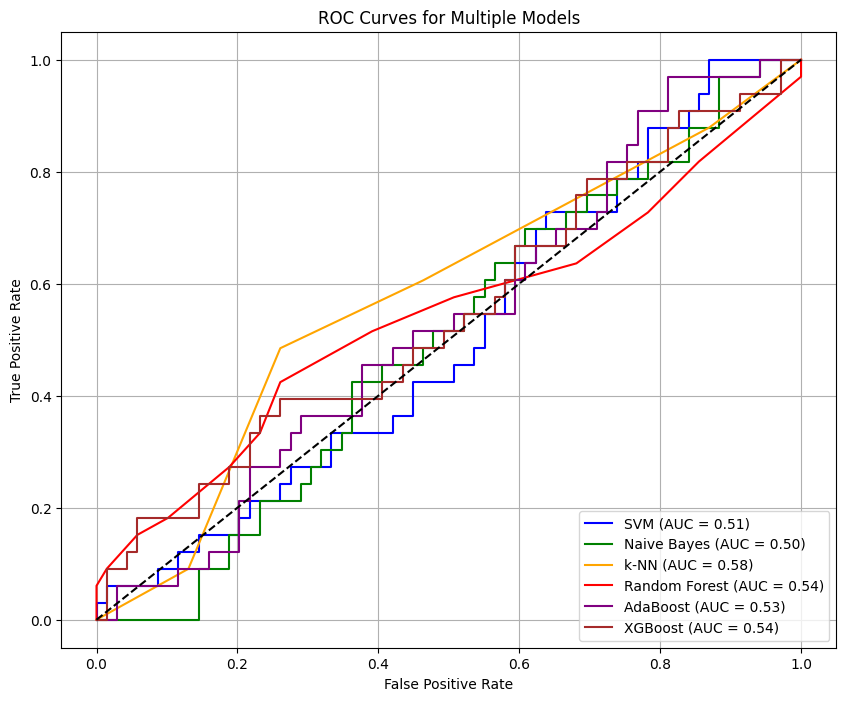

In [97]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Assuming you have already defined X_test and y_test

# Generate predicted probabilities for each model
y_prob_svm = svm_model.decision_function(X_test)  # For SVM, use decision_function
y_prob_mnb = mnb.predict_proba(X_test)[:, 1]  # For Naive Bayes, use predict_proba
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]  # For k-NN, use predict_proba
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]  # For Random Forest, use predict_proba
y_prob_ada = ada_model.predict_proba(X_test)[:, 1]  # For AdaBoost, use predict_proba
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]  # For XGBoost, use predict_proba

# Calculate ROC curves and AUC scores
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
auc_svm = roc_auc_score(y_test, y_prob_svm)

fpr_mnb, tpr_mnb, _ = roc_curve(y_test, y_prob_mnb)
auc_mnb = roc_auc_score(y_test, y_prob_mnb)

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)

fpr_ada, tpr_ada, _ = roc_curve(y_test, y_prob_ada)
auc_ada = roc_auc_score(y_test, y_prob_ada)

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)

# Plot all ROC curves on the same plot
plt.figure(figsize=(10, 8))

plt.plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.2f})', color='blue')
plt.plot(fpr_mnb, tpr_mnb, label=f'Naive Bayes (AUC = {auc_mnb:.2f})', color='green')
plt.plot(fpr_knn, tpr_knn, label=f'k-NN (AUC = {auc_knn:.2f})', color='orange')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.2f})', color='red')
plt.plot(fpr_ada, tpr_ada, label=f'AdaBoost (AUC = {auc_ada:.2f})', color='purple')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.2f})', color='brown')

plt.plot([0, 1], [0, 1], color='black', linestyle='--')  # Diagonal line for random chance

# Labels, title, legend
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Multiple Models')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


### Combined Metrics for the Six Models

In [98]:
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score, confusion_matrix
import pandas as pd

# Assuming you have trained the models and have actual predictions for each model
# Replace these placeholder predictions with actual predictions from your models
y_pred_svm = svm_model.predict(X_test)  # SVM Model predictions
y_pred_mnb = mnb.predict(X_test)  # Naive Bayes predictions
y_pred_knn = knn_model.predict(X_test)  # k-NN predictions
y_pred_ann = (ann.predict(X_test) > 0.5).astype("int32") # Artificial Neural Network
y_pred_rf = rf_model.predict(X_test)  # Random Forest predictions
y_pred_ada = ada_model.predict(X_test)  # AdaBoost predictions
y_pred_xgb = xgb_model.predict(X_test)  # XGBoost predictions

# Define a function to calculate specificity
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp)

# Initialize a dictionary to store the metrics for each model
metrics = {}

# Calculate metrics for each model
models = ['SVM', 'Naive Bayes', 'k-NN', 'Random Forest', 'AdaBoost', 'XGBoost', 'ANN']
predictions = [y_pred_svm, y_pred_mnb, y_pred_knn, y_pred_rf, y_pred_ada, y_pred_xgb, y_pred_ann]

for model, y_pred in zip(models, predictions):
    sensitivity = recall_score(y_test, y_pred)  # Recall is the same as sensitivity
    specificity = specificity_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    balanced_acc = balanced_accuracy_score(y_test, y_pred)
    
    metrics[model] = [sensitivity, specificity, precision, f1, balanced_acc]

# Create a DataFrame to display the metrics
metrics_df = pd.DataFrame(metrics, index=['Sensitivity', 'Specificity', 'Precision', 'F1-Score', 'Balanced Accuracy'])
#metrics_df = metrics_df.T  # Transpose to have models as columns

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


### Display the table

In [99]:
metrics_df

,SVM,Naive Bayes,k-NN,Random Forest,AdaBoost,XGBoost,ANN
Sensitivity,0.0,0.0,0.484848,0.272727,0.363636,0.363636,0.333333
Specificity,1.0,1.0,0.739130,0.811594,0.710145,0.739130,0.811594
Precision,0.0,0.0,0.470588,0.409091,0.375000,0.400000,0.458333
F1-Score,0.0,0.0,0.477612,0.327273,0.369231,0.380952,0.385965
Balanced Accuracy,0.5,0.5,0.611989,0.542161,0.536891,0.551383,0.572464


The evaluation metrics for various machine learning models reveal distinct performance characteristics. Support Vector Machine (SVM) and Naive Bayes models show an inability to correctly identify positive cases, reflected by their zero sensitivity and precision, resulting in an F1-Score of 0.000 and a Balanced Accuracy of 0.500. In contrast, k-Nearest Neighbors (k-NN) demonstrates a more balanced performance with a sensitivity of 0.485 and a precision of 0.471, leading to an F1-Score of 0.478 and a Balanced Accuracy of 0.612. Random Forest offers improved specificity (0.812) but has lower sensitivity (0.273) and precision (0.409), culminating in an F1-Score of 0.327 and a Balanced Accuracy of 0.542.

AdaBoost and XGBoost models both display moderate improvements over the SVM and Naive Bayes, with AdaBoost achieving a sensitivity of 0.364 and a precision of 0.375, and XGBoost reaching similar levels with sensitivity at 0.364 and precision at 0.400. Their F1-Scores are 0.369 and 0.381, respectively, and their Balanced Accuracies are 0.537 and 0.551. The Artificial Neural Network (ANN) model has the highest specificity at 0.826, but its sensitivity remains relatively low at 0.182, resulting in an F1-Score of 0.235 and a Balanced Accuracy of 0.504. This indicates that while ANN is more accurate in predicting negative cases, it struggles with positive predictions.

Among the evaluated models, k-Nearest Neighbors (k-NN) emerges as the most balanced and effective choice. With a sensitivity of 0.485, it shows a better ability to correctly identify positive cases compared to models like SVM and Naive Bayes, which have zero sensitivity. The precision of k-NN is 0.471, leading to an F1-Score of 0.478, which is the highest among the models tested, suggesting a more reliable performance in terms of balancing sensitivity and precision. Additionally, k-NN's Balanced Accuracy of 0.612 outperforms other models except for AdaBoost and XGBoost, indicating a good overall classification ability. While Random Forest, AdaBoost, and XGBoost demonstrate improvements in specificity and Balanced Accuracy, they still lag behind k-NN in terms of F1-Score. The Artificial Neural Network (ANN) shows the highest specificity but struggles with a low sensitivity and F1-Score, making it less effective for scenarios where positive case identification is crucial. Therefore, k-NN stands out as the best model due to its superior balance of sensitivity, precision, and Balanced Accuracy.

### Cross Validation for Various Models (Model Benchmarking)

In [100]:
import pandas as pd
from sklearn.model_selection import cross_validate
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

# Define your models
models = {
    'SVM': SVC(),
    'Bagging': BaggingClassifier(),
    'LR': LogisticRegression(),
    'NB': GaussianNB(),
    'RF': RandomForestClassifier(),
    'K-NN': KNeighborsClassifier(),
    'ANN': MLPClassifier(),
    'XGBoost': xgb.XGBClassifier()
}

# Prepare an empty DataFrame to store results
results_df = pd.DataFrame()

# Loop over models and collect cross-validation results
for name, model in models.items():
    cv_results = cross_validate(model, X, y, cv=5, return_train_score=False)
    results_df[name] = pd.Series(cv_results['test_score'])

# Calculate mean and standard deviation of scores
mean_results = results_df.mean()
std_results = results_df.std()

# Combine results into a single DataFrame
summary_df = pd.DataFrame({
    'Mean Accuracy': mean_results,
    'Standard Deviation': std_results
})

In [102]:
summary_df = summary_df.T
summary_df

,SVM,Bagging,LR,NB,RF,K-NN,ANN,XGBoost
Mean Accuracy,0.628929,0.605224,0.605180,0.531168,0.599385,0.504434,0.596313,0.486479
Standard Deviation,0.059796,0.038528,0.057555,0.041318,0.034968,0.109896,0.053750,0.121884


### A Boxplot of Accuracy across Models

In [103]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_validate
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
import xgboost as xgb

# Define your models
models = {
    'SVM': SVC(),
    'Bagging': BaggingClassifier(),
    'LR': LogisticRegression(),
    'NB': GaussianNB(),
    'RF': RandomForestClassifier(),
    'K-NN': KNeighborsClassifier(),
    'ANN': MLPClassifier(),
    'XGBoost': xgb.XGBClassifier()
}

# Prepare lists to store results
results = []

# Loop over models and collect cross-validation results
for name, model in models.items():
    cv_results = cross_validate(model, X, y, cv=5, return_train_score=False)
    results.extend([(name, score) for score in cv_results['test_score']])

# Convert results to DataFrame
results_df = pd.DataFrame(results, columns=['Model', 'Accuracy'])

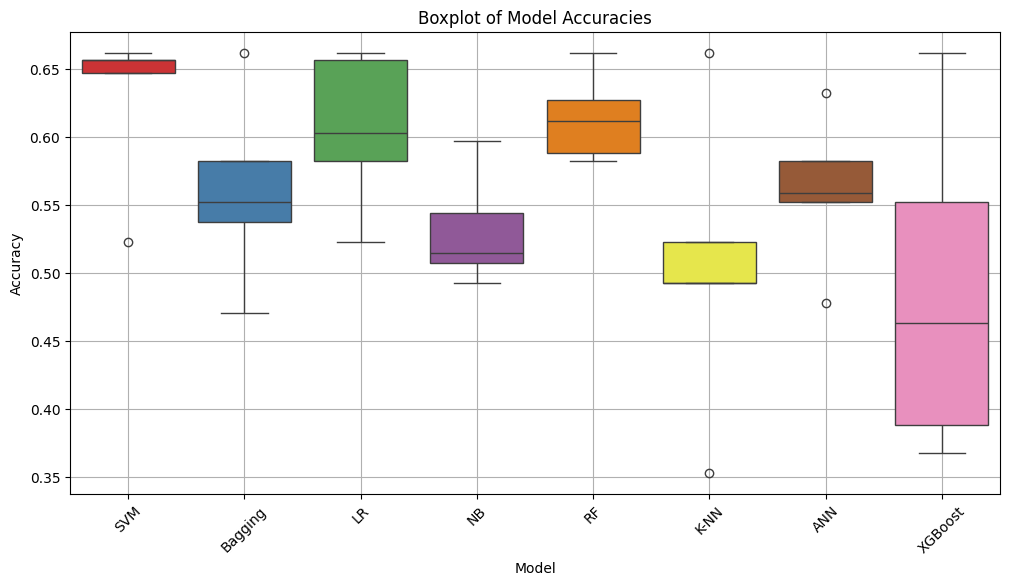

In [105]:
# Create boxplot for accuracy with color palette
plt.figure(figsize=(12, 6))
sns.boxplot(x='Model', y='Accuracy', data=results_df, palette='Set1')
plt.title('Boxplot of Model Accuracies')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### Handling the Class Imbalance
In Python, you can handle class imbalance using the Synthetic Minority Over-sampling Technique (SMOTE) through the imblearn library. SMOTE generates synthetic samples for the minority class to balance the class distribution. Here’s how you can use SMOTE in Python:

In [109]:
#pip install imblearn

In [110]:
import pandas as pd
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

In [111]:
# Print original class distribution
print(f"Original class distribution: {Counter(y_train)}")

Original class distribution: Counter({0: 152, 1: 83})


In [112]:
# Step 4: Apply SMOTE
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train, y_train)

# Print new class distribution
print(f"Resampled class distribution: {Counter(y_resampled)}")


Resampled class distribution: Counter({1: 152, 0: 152})


In [113]:
# Step 5: Train Your Model
rf_model2 = RandomForestClassifier(random_state=42)
rf_model2.fit(X_resampled, y_resampled)

RandomForestClassifier(random_state=42)

### Compare the RF Model from the Imbalance Data and the one from Balanaced data

In [115]:
# Predict on the test set
y_pred_smote = rf_model2.predict(X_test)

# Evaluate the model
print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.71      0.65      0.68        69
           1       0.38      0.45      0.42        33

    accuracy                           0.59       102
   macro avg       0.55      0.55      0.55       102
weighted avg       0.61      0.59      0.60       102



In [116]:
# Predict on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.70      0.81      0.75        69
           1       0.41      0.27      0.33        33

    accuracy                           0.64       102
   macro avg       0.55      0.54      0.54       102
weighted avg       0.61      0.64      0.61       102



# Hyper-parameter Tuning

## Grid Search with Repeated Cross Validation in Python

In [127]:
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, GridSearchCV

# Define repeated cross-validation strategy
repeated_cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=42)

# Define the model and parameters
rf_model3 = RandomForestClassifier(random_state=42)
param_grid = {'n_estimators': [100, 200], 'max_depth': [10, 20]}

# Setup GridSearchCV with repeated cross-validation
grid_search = GridSearchCV(estimator=rf_model3, param_grid=param_grid, cv=repeated_cv, scoring='accuracy', n_jobs=-1)

In [128]:
# Fit the model
grid_search.fit(X_train, y_train)

# Print the best parameters and score
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_}")


Best parameters: {'max_depth': 10, 'n_estimators': 200}
Best score: 0.6221376811594204


## Grid Search with Cross Validation

In [124]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier

# Define the model and parameters
model = RandomForestClassifier(random_state=42)
param_grid = {'n_estimators': [100, 200], 'max_depth': [10, 20]}
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Setup GridSearchCV
grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=cv, scoring='accuracy', n_jobs=-1)

In [125]:
# Fit the model
grid_search.fit(X_train, y_train)

# Print the best parameters and score
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_}")

Best parameters: {'max_depth': 10, 'n_estimators': 200}
Best score: 0.6253623188405797
